**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - CICESE  
Luis Felipe García Domínguez

## Práctica 3: Tarea de clasificación
### Predicción de deserción, permanencia y graduación en educación superior (Instituto Politécnico de Portalegre)

En esta tercera práctica construimos y comparamos cinco familias de clasificadores vistas en el curso (**Árbol de decisión**, **Naive Bayes**, **k vecinos más cercanos (kNN)**, **Máquinas de Soporte Vectorial (SVM)** y **Regresión Logística**) con el objetivo de predecir, **al cierre del primer semestre**, la situación final que tendrá un estudiante al término de la duración normal de su licenciatura:

- **`Dropout` (Desertor):** Abandona los estudios antes de concluir el programa.
- **`Enrolled` (Inscrito):** Continúa matriculado más allá de la duración normal sin haberse graduado ni dado de baja.
- **`Graduate` (Graduado):** Concluye satisfactoriamente su carrera en el tiempo esperado.

---

### Contexto y procedencia del conjunto de datos

- **¿Qué mide?**  
  Variables demográficas, socioeconómicas, macroeconómicas y de desempeño académico durante el primer y segundo semestre de estudiantes de 17 programas de licenciatura (agronomía, diseño, educación, enfermería, periodismo, administración, servicio social y tecnologías).
- **¿Quién lo recolectó?**  
  El **Instituto Politécnico de Portalegre** (Portugal), cruzando registros internos de control escolar con bases del Ministerio de Educación y Ciencia de Portugal (Realinho et al., 2022).
- **¿Cuándo se recolectó?**  
  Corresponde a las cohortes de ingreso comprendidas entre los ciclos escolares **2008/2009 y 2018/2019** (10 generaciones).
- **¿Cuál es la unidad de observación?**  
  Cada fila representa a un **estudiante de licenciatura** evaluado al final de la duración normativa de su plan de estudios.
- **Ficha oficial del repositorio:**  
  [UCI Machine Learning Repository — Predict Students' Dropout and Academic Success (Dataset ID: 697)](https://archive.ics.uci.edu/dataset/697)

---

## 1. Preparación del entorno y librerías

Cargamos las librerías necesarias para el manejo de datos, visualización y modelado con `scikit-learn`. Fijamos desde el inicio la semilla (`SEMILLA = 42`).

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, KBinsDiscretizer, FunctionTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, multilabel_confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB, CategoricalNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")

print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)
print("scikit-learn:", sklearn.__version__)

numpy       : 2.5.3
pandas      : 3.0.6
matplotlib  : 3.11.2
seaborn     : 0.13.2
scikit-learn: 1.9.1


Configuramos el estilo visual y la paleta de colores.

In [2]:
# Paleta de colores
AZUL_OSCURO = "#112057"
AZUL_MEDIO = "#3C51A9"
AZUL = "#7697CD"
AZUL_CLARO = "#BFD5EA"
NARANJA = "#E76A28"
ROJO = "#C0392B"
GRIS = "#5B6584"

MAPA_AZULES = LinearSegmentedColormap.from_list("azules", ["#FFFFFF", AZUL_MEDIO])

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
})

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 50)

SEMILLA = 42
CLASES = ["Dropout", "Enrolled", "Graduate"]

---

## 2. Análisis exploratorio de los datos

Los datos se encuentran divididos en dos archivos dentro de la carpeta `../data/`:
- `desercion-entrenamiento.csv`: Contiene **3,539 estudiantes** (el 80 % de los 4,424 registros originales), con el identificador `id`, los 36 atributos del estudio y la variable objetivo `Target`.
- `desercion-prueba.csv`: Contiene **885 estudiantes** (el 20 % restante) sin la columna `Target`, que utilizaremos al final para generar nuestras predicciones de evaluación.

Cargamos ambos conjuntos e inspeccionamos dimensiones, valores faltantes e intersección de columnas.

In [3]:
RUTA_DATOS = Path("../data")
entrena_crudo = pd.read_csv(RUTA_DATOS / "desercion-entrenamiento.csv")
prueba_crudo = pd.read_csv(RUTA_DATOS / "desercion-prueba.csv")

cols_solo_entrena = [c for c in entrena_crudo.columns if c not in prueba_crudo.columns]

print(f"Conjunto de entrenamiento : {entrena_crudo.shape[0]:,} filas × {entrena_crudo.shape[1]} columnas")
print(f"Conjunto de prueba        : {prueba_crudo.shape[0]:,} filas × {prueba_crudo.shape[1]} columnas")
print(f"Valores nulos (entrena)   : {entrena_crudo.isna().sum().sum()}")
print(f"Valores nulos (prueba)    : {prueba_crudo.isna().sum().sum()}")
print("\nColumnas presentes en entrenamiento pero NO en prueba:")
for c in cols_solo_entrena:
    print(f"  - {c}")

Conjunto de entrenamiento : 3,539 filas × 38 columnas
Conjunto de prueba        : 885 filas × 31 columnas
Valores nulos (entrena)   : 0
Valores nulos (prueba)    : 0

Columnas presentes en entrenamiento pero NO en prueba:
  - Curricular units 2nd sem (credited)
  - Curricular units 2nd sem (enrolled)
  - Curricular units 2nd sem (evaluations)
  - Curricular units 2nd sem (approved)
  - Curricular units 2nd sem (grade)
  - Curricular units 2nd sem (without evaluations)
  - Target


### Información disponible al momento de decidir

Al contrastar las columnas de ambos archivos aparece un primer punto interesante para el diseño experimental: el archivo de prueba tiene **30 atributos predictores** (más `id`), mientras que el de entrenamiento tiene **36 atributos** (más `id` y `Target`). Las 6 columnas que no están en el conjunto de prueba corresponden al **desempeño académico del segundo semestre**.

Para construir nuestros cinco clasificadores principales debemos eliminar de las entradas de entrenamiento la columna `id` y los 6 atributos del segundo semestre. La columna `id` se descarta porque es un número de registro sin valor predictivo. Por su parte, las 6 variables del segundo semestre se excluyen porque solo vamos a predecir la situación del alumno **al cierre del primer semestre**; además, como no están disponibles en `desercion-prueba.csv`, un clasificador que dependa de ellas no podría evaluar a los 885 estudiantes de prueba. Sin embargo, se reservarán esas 6 columnas para la Sección 7, donde veremos cuánto mejoraría el predictor si la universidad decidiera esperar medio año más antes de actuar.

---

### Distribución de la variable objetivo (`Target`)

Revisamos cómo se reparten las tres clases en los 3,539 estudiantes de entrenamiento.

,Estudiantes,Porcentaje (%)
Target,,
Dropout,1137,32.13
Enrolled,635,17.94
Graduate,1767,49.93


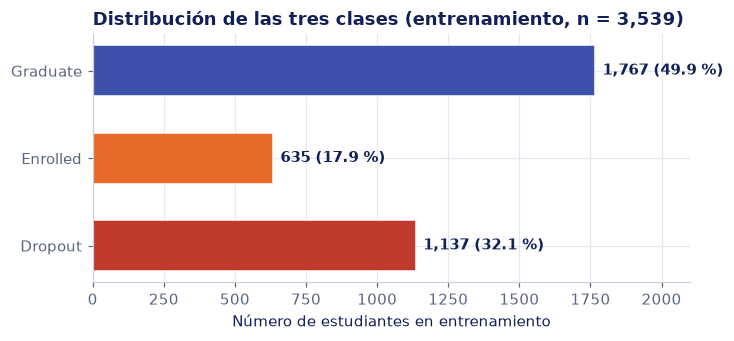

In [4]:
conteo_clases = entrena_crudo["Target"].value_counts().reindex(CLASES)
prop_clases = (entrena_crudo["Target"].value_counts(normalize=True).reindex(CLASES) * 100).round(2)

resumen_clases = pd.DataFrame({
    "Estudiantes": conteo_clases,
    "Porcentaje (%)": prop_clases
})
display(resumen_clases)

fig, ax = plt.subplots(figsize=(6.8, 3.2))
colores_clases = [ROJO, NARANJA, AZUL_MEDIO]
barras = ax.barh(CLASES, conteo_clases, color=colores_clases, height=0.58, edgecolor="white")

for barra, cant, pct in zip(barras, conteo_clases, prop_clases):
    ax.text(
        barra.get_width() + 25,
        barra.get_y() + barra.get_height() / 2,
        f"{cant:,} ({pct:.1f} %)",
        va="center", ha="left", color=AZUL_OSCURO, fontweight="bold", fontsize=9.5
    )

ax.set_xlim(0, 2100)
ax.set_xlabel("Número de estudiantes en entrenamiento")
ax.set_title("Distribución de las tres clases (entrenamiento, n = 3,539)")
plt.tight_layout()
plt.show()

**Lectura.** La distribución de clases presenta un desbalance moderado pero importante para el modelado:
- Casi la mitad de la matrícula (49.93 %, 1,767 estudiantes) logra graduarse en tiempo (`Graduate`).
- Cerca de una tercera parte (32.13 %, 1,137 estudiantes) abandona sus estudios (`Dropout`).
- La clase `Enrolled` (17.94 %, 635 estudiantes) es minoritaria: hay casi 3 graduados por cada alumno todavía inscrito.

Como la métrica de evaluación de la práctica es el **F1 macro** (promedio del F1 de las tres clases, dando el mismo peso a cada una sin importar la distribución), ignorar a la clase `Enrolled` afectaría el resultado global. Un clasificador _ingenuo_ que predija siempre la clase mayoritaria (`Graduate`) obtendría un 49.9 % de exactitud, pero apenas alcanzaría un F1 macro de:

$$\frac{1}{3} \left(\frac{2 \times 0.499}{1 + 0.499}\right) \approx 0.222$$

---

### Clasificación del tipo de cada atributo

Al inspeccionar los valores del CSV observamos que todas las columnas predictoras vienen guardadas como números (`int64` o `float64`). Sin embargo, al revisar la documentación del dataset, vemos que varios números enteros son códigos administrativos.

Para darle a cada algoritmo el tratamiento correcto, clasificamos los 30 atributos disponibles al cierre del primer semestre (más los 6 del segundo semestre) en la siguiente tabla:

In [5]:
NOMINALES_MULTICLASE = [
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation"
]

BINARIOS = [
    "Daytime/evening attendance", "Displaced", "Educational special needs",
    "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder", "International"
]

NUMERICOS_DISCRETOS_1S = [
    "Application order", "Age at enrollment",
    "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (without evaluations)"
]

NUMERICOS_CONTINUOS_1S = [
    "Previous qualification (grade)", "Admission grade",
    "Curricular units 1st sem (grade)",
    "Unemployment rate", "Inflation rate", "GDP"
]

NUMERICOS_1S = NUMERICOS_DISCRETOS_1S + NUMERICOS_CONTINUOS_1S
ATRIBUTOS_2S = [c for c in entrena_crudo.columns if "2nd sem" in c]
COLUMNAS_1S = [c for c in prueba_crudo.columns if c != "id"]

# Verificación de que están contabilizados los 36 atributos
assert len(NOMINALES_MULTICLASE) + len(BINARIOS) + len(NUMERICOS_1S) == 30
assert len(ATRIBUTOS_2S) == 6

grupos_atributos = [
    ("Nominal multiclase (código entero)", "1er semestre", NOMINALES_MULTICLASE),
    ("Nominal binario (0/1)", "1er semestre", BINARIOS),
    ("Numérico discreto (conteos / edad)", "1er semestre", NUMERICOS_DISCRETOS_1S),
    ("Numérico continuo (notas / macro)", "1er semestre", NUMERICOS_CONTINUOS_1S),
    ("Numérico de 2do semestre", "Solo entrenamiento", ATRIBUTOS_2S),
]

tabla_atributos = pd.DataFrame([
    {
        "Grupo de variables": nombre_grupo,
        "Disponibilidad": disp,
        "Cantidad": len(cols),
        "Columnas": ", ".join(cols),
    }
    for nombre_grupo, disp, cols in grupos_atributos
])

display(tabla_atributos)

,Grupo de variables,Disponibilidad,Cantidad,Columnas
0,Nominal multiclase (código entero),1er semestre,9,"Marital status, Application mode, Course, Prev..."
1,Nominal binario (0/1),1er semestre,8,"Daytime/evening attendance, Displaced, Educati..."
2,Numérico discreto (conteos / edad),1er semestre,7,"Application order, Age at enrollment, Curricul..."
3,Numérico continuo (notas / macro),1er semestre,6,"Previous qualification (grade), Admission grad..."
4,Numérico de 2do semestre,Solo entrenamiento,6,"Curricular units 2nd sem (credited), Curricula..."


### Algunas dudas sobre las variables

Al explorar el comportamiento de los 30 atributos del primer semestre me surgieron dos dudas que fueron importantes para configurar los *Pipelines*:

1. **¿Hay códigos nominales en el conjunto de prueba que no aparecen en entrenamiento?**  
   Como varios atributos nominales tienen muchas categorías (por ejemplo, la ocupación del padre tiene 45 códigos distintos y la de la madre 31), revisé si en los 885 alumnos de `desercion-prueba.csv` aparecían categorías nuevas o códigos con muy pocos estudiantes.

2. **¿Cómo se separan las tres clases en el primer semestre y dónde está el traslape?**  
   Visualizamos las variables más representativas del primer semestre para entender por qué ciertos alumnos son fáciles de clasificar y otros se confunden entre sí.

,Atributo nominal,Categorías en entrena,Categorías con < 8 alumnos,Códigos en prueba NO vistos en entrena
0,Marital status,6,2,Ninguno
1,Application mode,17,3,[26]
2,Course,17,0,Ninguno
3,Previous qualification,17,7,Ninguno
4,Nacionality,18,13,"[13, 14, 32]"
5,Mother's qualification,26,14,"[10, 18, 27]"
6,Father's qualification,32,20,"[13, 18]"
7,Mother's occupation,31,17,[171]
8,Father's occupation,45,31,[101]


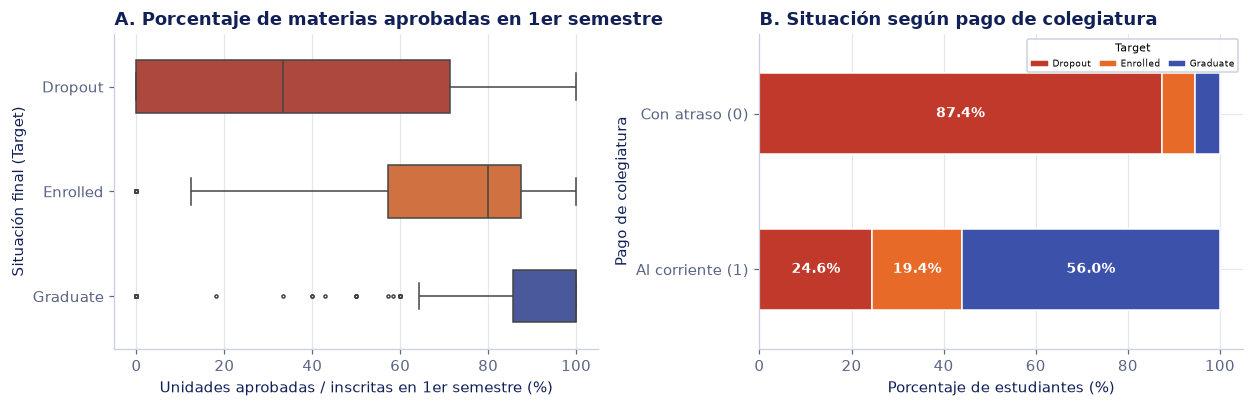

In [6]:
# 1. Revisión de categorías en prueba y en entrenamiento
revision_nominales = []
for col in NOMINALES_MULTICLASE:
    cat_entrena = set(entrena_crudo[col].unique())
    cat_prueba = set(prueba_crudo[col].unique())
    nuevas_en_prueba = sorted(list(cat_prueba - cat_entrena))
    raras_en_entrena = (entrena_crudo[col].value_counts() < 8).sum()
    revision_nominales.append({
        "Atributo nominal": col,
        "Categorías en entrena": len(cat_entrena),
        "Categorías con < 8 alumnos": int(raras_en_entrena),
        "Códigos en prueba NO vistos en entrena": nuevas_en_prueba if nuevas_en_prueba else "Ninguno"
    })

display(pd.DataFrame(revision_nominales))

# 2. Visualización del comportamiento en el 1er semestre
df_eda = entrena_crudo.copy()
insc = df_eda["Curricular units 1st sem (enrolled)"]
aprob = df_eda["Curricular units 1st sem (approved)"]
df_eda["tasa_aprob_1s"] = np.where(insc > 0, (aprob / insc) * 100, 0.0)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))

# Panel 1: Tasa de aprobación del 1er semestre por clase
sns.boxplot(
    data=df_eda, x="tasa_aprob_1s", y="Target", order=CLASES,
    palette=[ROJO, NARANJA, AZUL_MEDIO], width=0.5, ax=axes[0], fliersize=2
)
axes[0].set_title("A. Porcentaje de materias aprobadas en 1er semestre")
axes[0].set_xlabel("Unidades aprobadas / inscritas en 1er semestre (%)")
axes[0].set_ylabel("Situación final (Target)")

# Panel 2: Situación con respecto al pago de colegiaturas
ct_colegiatura = (
    pd.crosstab(df_eda["Tuition fees up to date"].map({0: "Con atraso (0)", 1: "Al corriente (1)"}), df_eda["Target"], normalize="index")[CLASES] * 100
)
ct_colegiatura.plot(kind="barh", stacked=True, color=[ROJO, NARANJA, AZUL_MEDIO], ax=axes[1], width=0.52, edgecolor="white")
axes[1].set_title("B. Situación según pago de colegiatura")
axes[1].set_xlabel("Porcentaje de estudiantes (%)")
axes[1].set_ylabel("Pago de colegiatura")
axes[1].legend(
    title="Target",
    loc="upper right",
    ncol=3,
    fontsize=6,
    title_fontsize=7,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.4,
    columnspacing=0.8,
    handletextpad=0.4,
)

for n_fila, (_, fila) in enumerate(ct_colegiatura.iterrows()):
    acum = 0
    for val in fila:
        if val >= 8:
            axes[1].text(acum + val / 2, n_fila, f"{val:.1f}%", va="center", ha="center", color="white", fontweight="bold", fontsize=9)
        acum += val

plt.tight_layout()
plt.show()

**Lectura.** Obtuvimos información valiosa para diseñar el preprocesamiento:
1. La tabla muestra que en 6 de los 9 atributos nominales existen códigos en el conjunto de prueba que no aparecen en el entrenamiento (como las nacionalidades `13, 14, 32` o la vía de aplicación `26`). Además, en variables como la ocupación y escolaridad de los padres, más de la mitad de las categorías tienen menos de 8 estudiantes en todo el entrenamiento. Si usáramos un `OneHotEncoder` básico (sin manejo de desconocidos), el modelo fallaría al predecir la prueba, y si dejáramos una columna binaria para cada código raro de 1 o 2 alumnos, introduciríamos ruido.

2. En el **Panel A** se aprecia que los graduados (`Graduate`) aprueban en mediana el 100% de sus materias del primer semestre, mientras que la mediana de los desertores (`Dropout`) ronda el 30–40%. En cambio, los alumnos de la clase `Enrolled` se distribuyen justo en la zona intermedia (aprueban entre el 50 % y el 80 % de su carga), traslapándose con los desertores que sí aprobaron algunas materias y con algunos graduados. Por otra parte, el **Panel B** muestra que entre quienes tienen atraso en el pago de colegiatura (`Tuition fees up to date = 0`), el **86.6 % termina desertando**.

Revisamos también cómo cambia la proporción de desertores según la edad de ingreso (comparando a quienes entran antes de los 23 años contra quienes ingresan de 23 años o más) y según si el estudiante registra adeudos (`Debtor`).

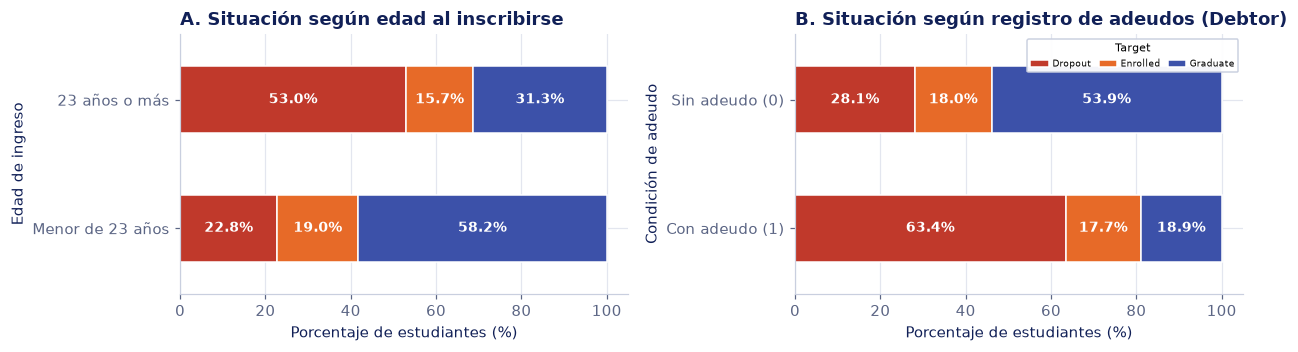

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3))

# Panel A: Grupo de edad al inscribirse (< 23 vs >= 23 años)
grupo_edad = np.where(df_eda["Age at enrollment"] >= 23, "23 años o más", "Menor de 23 años")
ct_edad = (
    pd.crosstab(grupo_edad, df_eda["Target"], normalize="index")
    .reindex(["Menor de 23 años", "23 años o más"])[CLASES] * 100
)
ct_edad.plot(kind="barh", stacked=True, color=[ROJO, NARANJA, AZUL_MEDIO], ax=axes[0], width=0.52, edgecolor="white", legend=False)
axes[0].set_title("A. Situación según edad al inscribirse")
axes[0].set_xlabel("Porcentaje de estudiantes (%)")
axes[0].set_ylabel("Edad de ingreso")

for n_fila, (_, fila) in enumerate(ct_edad.iterrows()):
    acum = 0
    for val in fila:
        if val >= 8:
            axes[0].text(acum + val / 2, n_fila, f"{val:.1f}%", va="center", ha="center", color="white", fontweight="bold", fontsize=9)
        acum += val

# Panel B: Situación según registro de adeudos (Debtor)
ct_deudor = (
    pd.crosstab(df_eda["Debtor"].map({0: "Sin adeudo (0)", 1: "Con adeudo (1)"}), df_eda["Target"], normalize="index")
    .reindex(["Con adeudo (1)", "Sin adeudo (0)"])[CLASES] * 100
)
ct_deudor.plot(kind="barh", stacked=True, color=[ROJO, NARANJA, AZUL_MEDIO], ax=axes[1], width=0.52, edgecolor="white")
axes[1].set_title("B. Situación según registro de adeudos (Debtor)")
axes[1].set_xlabel("Porcentaje de estudiantes (%)")
axes[1].set_ylabel("Condición de adeudo")
axes[1].legend(
    title="Target",
    loc="upper right",
    ncol=3,
    fontsize=6,
    title_fontsize=7,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.4,
    columnspacing=0.8,
    handletextpad=0.4,
)

for n_fila, (_, fila) in enumerate(ct_deudor.iterrows()):
    acum = 0
    for val in fila:
        if val >= 8:
            axes[1].text(acum + val / 2, n_fila, f"{val:.1f}%", va="center", ha="center", color="white", fontweight="bold", fontsize=9)
        acum += val

plt.tight_layout()
plt.show()

**Lectura.** Ambos paneles muestran cortes claros que aprovecharemos en la siguiente sección:
1. En el **Panel A**, mientras que entre los alumnos que ingresan antes de los 23 años solo deserta el **22.8%** (y se gradúa el **58.2%**), entre quienes ingresan con 23 años o más la deserción sube a más del doble (**53.0%**). Esto justifica agregar en el preprocesamiento el indicador binario `mayor_23_ingreso` y dividir la edad por rangos en la Regresión Logística.

2. En el **Panel B**, tener un adeudo registrado (`Debtor = 1`) eleva la deserción del **28.1% al 63.4%**, razón por la cual en la Sección 3 combinamos esta variable con el atraso de colegiatura en el indicador `deudor_sin_colegiatura`.

Por último, revisamos la matriz de correlación entre las variables académicas del primer semestre para identificar qué tan redundantes son entre sí antes de entrenar los clasificadores.

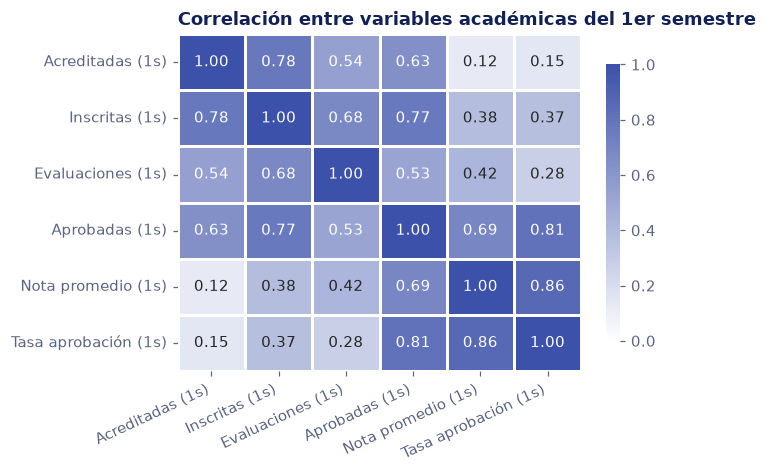

In [8]:
cols_acad_1s = [
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "tasa_aprob_1s",
]
etiquetas_acad = [
    "Acreditadas (1s)",
    "Inscritas (1s)",
    "Evaluaciones (1s)",
    "Aprobadas (1s)",
    "Nota promedio (1s)",
    "Tasa aprobación (1s)",
]

corr_acad = df_eda[cols_acad_1s].corr()
corr_acad.index = etiquetas_acad
corr_acad.columns = etiquetas_acad

fig, ax = plt.subplots(figsize=(6.4, 4.4))
sns.heatmap(
    corr_acad, annot=True, fmt=".2f", cmap=MAPA_AZULES, vmin=0, vmax=1,
    cbar_kws={"shrink": 0.82}, linewidths=0.8, ax=ax
)
ax.set_title("Correlación entre variables académicas del 1er semestre")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Lectura.** Las variables académicas del primer semestre presentan correlaciones altas entre sí: por ejemplo, las materias inscritas con las acreditadas (`0.78`) y con las aprobadas (`0.77`), o la tasa de aprobación con la nota promedio (`0.86`) y con las materias aprobadas (`0.81`). En nuestra metodología, esto:

1. Explica por qué **Naive Bayes** tendrá un techo de desempeño más bajo que la Regresión Logística o el SVM: al asumir que todas las columnas son independientes, multiplica información académica repetida.

2. Nos da certeza sobre la importancia de usar regularización ($L_2$ / $L_1$) en la Regresión Logística para repartir los pesos entre variables correlacionadas sin que crezcan en exceso.

---

## 3. Diseño del preprocesamiento y extracción de indicadores (`Pipeline`)

### Resumir indicadores del primer semestre dentro del `Pipeline`

En el conjunto original, el rendimiento del primer semestre se desglosa en conteos como: cuántas materias inscribió el estudiante (`enrolled`), cuántas evaluaciones presentó (`evaluations`) y cuántas aprobó (`approved`). Sin embargo, la carga normal de primer semestre varía según la carrera (ya que en algunas se inscriben más materias que en otras).

Para un modelo lineal, de distancias o probabilístico, saber que un alumno aprobó 4 materias es ambiguo si no se compara directamente con cuántas inscribió. Por ello, de manera similar a lo que aplicamos en la ingeniería de características de la Práctica 2, incluimos como primer paso de preprocesamiento de todos los *Pipelines* una función (`FunctionTransformer(agregar_indicadores_1er_semestre)`) que calcula las relaciones e indicadores académicos/financieros usando solo datos del primer semestre:

- **Razones y conteos:** 
    - `tasa_aprobacion_1s` ($\frac{aprobadas}{inscritas}$)

    - `tasa_aprob_eval_1s` ($\frac{aprobadas}{evaluadas}$)

    - `tasa_evaluacion_1s` ($\frac{evaluadas}{inscritas}$)
    - `reprobadas_1s` ($inscritas - aprobadas$)
    - `eval_fallidas_1s` ($evaluadas - aprobadas$)
    - `eval_extra_1s` (exámenes extraordinarios por encima de las materias inscritas)
    - `puntos_totales_1s` ($aprobadas \cdot nota$)
    - `dif_admision_previa` ($admission \ grade - Previous \ qualification \ (grade)$).

- **Indicadores binarios académicos y financieros:**
    - Si se inscribió a 0 materias (`sin_unidades_1s`)
    - Si tiene promedio de cero (`nota_cero_1s`)
    - Si aprobó el 100 % de su carga (`todo_aprobado_1s`)
    - Si reprobó todo (`nada_aprobado_1s`)
    - Si aprobó parcialmente (`aprobacion_parcial_1s`: reprobó 1–2 materias vs. 3 o más, que distingue muy bien a un alumno `Enrolled` que solo se atrasa de un `Dropout`)
    - Si combina adeudo con atraso de colegiatura (`deudor_sin_colegiatura`).

Al concentrar esta función dentro de `FunctionTransformer` como primer paso del `Pipeline`, la transformación se aplica dentro de cada pliegue de validación cruzada y al evaluar el conjunto de prueba, sin modificar los archivos originales ni causar fuga de información (*data leakage*).

In [9]:
X = entrena_crudo[COLUMNAS_1S].copy()
y = entrena_crudo["Target"].copy()
X_prueba_final = prueba_crudo[COLUMNAS_1S].copy()

# Definimos los mismos 10 pliegues estratificados para comparar los 5 clasificadores en igualdad de condiciones
pliegues = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)


def agregar_indicadores_1er_semestre(df):
    '''Construye indicadores de aprovechamiento del 1er semestre'''
    df = df.copy()
    inscritas = df["Curricular units 1st sem (enrolled)"]
    aprobadas = df["Curricular units 1st sem (approved)"]
    evaluadas = df["Curricular units 1st sem (evaluations)"]
    nota = df["Curricular units 1st sem (grade)"]

    # Proporciones de aprobación y conteos de materias reprobadas
    df["tasa_aprobacion_1s"] = np.where(inscritas > 0, aprobadas / inscritas, 0.0)
    df["tasa_aprob_eval_1s"] = np.where(evaluadas > 0, aprobadas / evaluadas, 0.0)
    df["tasa_evaluacion_1s"] = np.where(inscritas > 0, evaluadas / inscritas, 0.0)
    df["reprobadas_1s"] = np.maximum(0, inscritas - aprobadas)
    df["eval_fallidas_1s"] = np.maximum(0, evaluadas - aprobadas)
    df["eval_extra_1s"] = np.maximum(0, evaluadas - inscritas)

    # Indicadores de situación en el 1er semestre
    df["sin_unidades_1s"] = (inscritas == 0).astype(int)
    df["nota_cero_1s"] = (nota == 0).astype(int)
    df["todo_aprobado_1s"] = ((inscritas > 0) & (aprobadas == inscritas)).astype(int)
    df["nada_aprobado_1s"] = ((inscritas > 0) & (aprobadas == 0)).astype(int)
    df["aprobacion_parcial_1s"] = ((aprobadas > 0) & (aprobadas < inscritas)).astype(int)
    df["reprobo_una_o_dos_1s"] = ((inscritas > 0) & ((inscritas - aprobadas).isin([1, 2]))).astype(int)
    df["reprobo_tres_o_mas_1s"] = ((inscritas - aprobadas) >= 3).astype(int)

    # Desempeño e indicadores socioeconómicos
    df["puntos_totales_1s"] = aprobadas * nota
    df["dif_admision_previa"] = df["Admission grade"] - df["Previous qualification (grade)"]
    df["deudor_sin_colegiatura"] = ((df["Debtor"] == 1) | (df["Tuition fees up to date"] == 0)).astype(int)
    df["colegiatura_y_todo_aprob"] = ((df["Tuition fees up to date"] == 1) & (df["todo_aprobado_1s"] == 1)).astype(int)
    df["mayor_23_ingreso"] = (df["Age at enrollment"] >= 23).astype(int)
    return df


# Identificamos las listas de columnas tras la transformación para alimentar los ColumnTransformer
muestra_transformada = agregar_indicadores_1er_semestre(X.head(5))
NUEVAS_BIN = [
    "sin_unidades_1s", "nota_cero_1s", "todo_aprobado_1s",
    "nada_aprobado_1s", "aprobacion_parcial_1s",
    "reprobo_una_o_dos_1s", "reprobo_tres_o_mas_1s",
    "deudor_sin_colegiatura", "colegiatura_y_todo_aprob", "mayor_23_ingreso"
]
NUEVAS_NUM = [c for c in muestra_transformada.columns if c not in COLUMNAS_1S and c not in NUEVAS_BIN]

NUMERICOS_TOTAL = NUMERICOS_1S + NUEVAS_NUM
BINARIOS_TOTAL = BINARIOS + NUEVAS_BIN

print(f"Atributos originales de 1er semestre : {len(COLUMNAS_1S)}")
print(f"Indicadores derivados agregados      : {len(NUEVAS_NUM)} numéricos + {len(NUEVAS_BIN)} binarios = {len(NUEVAS_NUM) + len(NUEVAS_BIN)}")
print(f"Total de variables de entrada        : {muestra_transformada.shape[1]}")

Atributos originales de 1er semestre : 30
Indicadores derivados agregados      : 8 numéricos + 10 binarios = 18
Total de variables de entrada        : 48


### ¿Conviene usar `class_weight="balanced"` o pesos moderados?

Nos piden explorar los pesos por clase (`class_weight`) en los tres clasificadores que los admiten: **Árbol de decisión**, **SVM** y **Regresión Logística**. Como se vio en el notebook sobre *Máquinas de soporte vectorial*, la opción `class_weight="balanced"` asigna a cada clase $k$ un peso inversamente proporcional a su frecuencia: $w_k = \frac{n}{c \cdot n_k}$.

Antes de hacer las búsquedas, calculamos cuánto valen esos pesos en el conjunto de entrenamiento y surge la duda: ¿qué pasa si el peso de `balanced` es mayor para la clase `Enrolled`?

In [10]:
pesos_balanceados = compute_class_weight("balanced", classes=np.array(CLASES), y=y)
PESOS_SUAVES = {"Dropout": 0.95, "Enrolled": 1.60, "Graduate": 0.75}

tabla_pesos = pd.DataFrame({
    "Estudiantes (n_k)": y.value_counts()[CLASES].to_numpy(),
    "Peso sin ajuste (None)": [1.0, 1.0, 1.0],
    "Peso 'balanced' n/(c·n_k)": pesos_balanceados.round(3),
    "Peso moderado propuesto": [PESOS_SUAVES[c] for c in CLASES],
}, index=CLASES)

display(tabla_pesos)

,Estudiantes (n_k),Peso sin ajuste (None),Peso 'balanced' n/(c·n_k),Peso moderado propuesto
Dropout,1137,1.0,1.038,0.95
Enrolled,635,1.0,1.858,1.60
Graduate,1767,1.0,0.668,0.75


**Lectura.** La tabla nos da un detalle interesante: el esquema `balanced` le da a cada estudiante de la clase `Enrolled` un peso de **1.858**, casi el triple que a un estudiante `Graduate` (**0.668**). Como vimos en el análisis exploratorio, `Enrolled` es una clase intermedia que se traslapa con `Dropout` y `Graduate`. Cuando se multiplica su costo de error por 1.858, el clasificador podría volverse demasiado agresivo prediciendo `Enrolled`, lo que aumenta las falsas alarmas y reduce la precisión de esa clase y la sensibilidad de las otras dos.

Por esta razón, además de evaluar `class_weight=None` (1:1:1) y `class_weight="balanced"` (1.04 : 1.86 : 0.67), se incluye como tercer candidato un esquema de **pesos moderados**, que mejora la detección de la clase minoritaria `Enrolled` sin llenar de falsos positivos a las demás.

---

### Resumen y justificación del preprocesamiento de cada clasificador

Cada familia de algoritmos trabaja de forma distinta con las variables de entrada, por lo que adaptamos el preprocesamiento a lo que necesita cada modelo:

| Clasificador | Nominales | Numéricas | Paso adicional | Justificación |
| :--- | :--- | :--- | :--- | :--- |
| **1. Árbol de decisión** | `OneHotEncoder` | Sin cambio (`passthrough`) | Ninguno | Como el árbol solo hace preguntas de corte (ej. *¿nota $\le 12$?*), cambiar la escala de los números no altera sus divisiones. Solo pasamos las nominales a columnas `0/1` para que no tome el código de una carrera como si fuera una cantidad mayor o menor que otra. |
| **2. Naive Bayes** | `OrdinalEncoder` / `OneHotEncoder` | `KBinsDiscretizer` (o `StandardScaler`) | Discretización por cuantiles | Ajustar campanas normales (`GaussianNB`) falla cuando hay muchas columnas `0/1` poco frecuentes. Agrupar las variables numéricas en intervalos permite que `CategoricalNB` cuente frecuencias por rango directamente. |
| **3. k Vecinos (kNN)** | `OneHotEncoder` | `StandardScaler` | `SelectKBest` (40 atributos) | Como mide distancias entre alumnos, si no escalamos, una nota de `0–200` pesaría 200 veces más que una beca `0–1`. Además, filtramos las 40 columnas más informativas para que las categorías poco relevantes no ensucien la distancia. |
| **4. SVM (`SVC`)** | `OneHotEncoder` | `StandardScaler` | Ninguno | El kernel `rbf` también calcula distancias entre estudiantes para trazar la frontera; estandarizar pone a todas las variables numéricas en igualdad de condiciones antes de ajustar $C$ y $\gamma$. |
| **5. Regresión Logística** | `OneHotEncoder` | `StandardScaler` | `KBinsDiscretizer` (5 rangos en 9 variables) | Escalamos para que la regularización castigue parejo a todas las variables, y partimos las 9 numéricas principales en 5 rangos para que el modelo pueda darle un peso distinto a cada escalón. |

---

## 4. Optimización de hiperparámetros por clasificador

En esta sección llevamos cada uno de los cinco clasificadores a su mejor versión mediante validación cruzada estratificada de 10 pliegues (`pliegues`), evaluamos **al menos 50 configuraciones por clasificador** con el **F1 macro** como métrica objetivo y verificando gráficamente que la búsqueda haya alcanzado una meseta de convergencia.

Aunque también se podría usar búsqueda aleatoria o bayesiana (como Optuna), aquí optamos por búsqueda en malla (`GridSearchCV`) por dos razones prácticas:

- Porque los cinco modelos son rápidos de entrenar en este conjunto de datos (tardan menos de un minuto cada uno), así que podemos probar todas las combinaciones sin problema.
- Porque al evaluar el cruce completo de valores podemos dejar fijos los demás hiperparámetros al graficar, lo que nos da curvas de meseta más limpias y fáciles de comparar que una nube de puntos dispersos.

---

### 4.1. Árbol de decisión (`DecisionTreeClassifier`)

Para el árbol de decisión codificamos los 9 atributos nominales con `OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist")` para no imponer un orden falso entre los códigos numéricos de carreras u ocupaciones, y dejamos pasar las variables numéricas y binarias en su escala original (`passthrough`), ya que la impureza de Gini y la entropía solo dependen del ordenamiento de los valores y no de su magnitud.

Aquí, se evalúan **432 configuraciones**, determinadas por los cuatro hiperparámetros requeridos:
- **Criterio de partición (`criterion`):** `["gini", "entropy"]`.
- **Profundidad máxima (`max_depth`):** `[3, 4, 5, 6, 7, 8, 10, 12, None]` (se incluye el árbol sin límite de profundidad para comparar el sobreajuste).
- **Tamaño mínimo de hoja (`min_samples_leaf`):** `[5, 10]`.
- **Poda por complejidad-costo (`ccp_alpha`):** `[0.0, 0.001, 0.002, 0.004]`.
- **Pesos por clase (`class_weight`):** `[None, "balanced", PESOS_SUAVES]`.

Primero obtenemos el árbol de decisión.

In [11]:
pre_arbol = ColumnTransformer([
    ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False), NOMINALES_MULTICLASE),
    ("num", "passthrough", NUMERICOS_TOTAL),
    ("bin", "passthrough", BINARIOS_TOTAL),
])

pipe_arbol = Pipeline([
    ("indicadores", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_arbol),
    ("clf", DecisionTreeClassifier(random_state=SEMILLA)),
])

rejilla_arbol = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [3, 4, 5, 6, 7, 8, 10, 12, None],
    "clf__min_samples_leaf": [5, 10],
    "clf__ccp_alpha": [0.0, 0.001, 0.002, 0.004],
    "clf__class_weight": [None, "balanced", PESOS_SUAVES],
}

inicio = time.perf_counter()
busqueda_arbol = GridSearchCV(
    pipe_arbol, rejilla_arbol, cv=pliegues, scoring="f1_macro", n_jobs=-1, return_train_score=True
).fit(X, y)
tiempo_arbol = time.perf_counter() - inicio

res_arbol = pd.DataFrame(busqueda_arbol.cv_results_)
n_configs_arbol = len(res_arbol)

print(f"Configuraciones evaluadas : {n_configs_arbol} (en {tiempo_arbol:.1f} s)")
print(f"Mejor F1 macro (VC 10)    : {busqueda_arbol.best_score_:.4f}")
print("Mejores hiperparámetros   :")
for k, v in busqueda_arbol.best_params_.items():
    print(f"  {k}: {v}")

Configuraciones evaluadas : 432 (en 40.2 s)
Mejor F1 macro (VC 10)    : 0.6550
Mejores hiperparámetros   :
  clf__ccp_alpha: 0.002
  clf__class_weight: {'Dropout': 0.95, 'Enrolled': 1.6, 'Graduate': 0.75}
  clf__criterion: entropy
  clf__max_depth: 6
  clf__min_samples_leaf: 10


Visualizamos cómo cambia el F1 Macro según la profundidad y cómo se comporta en validación una vez que se poda el árbol.

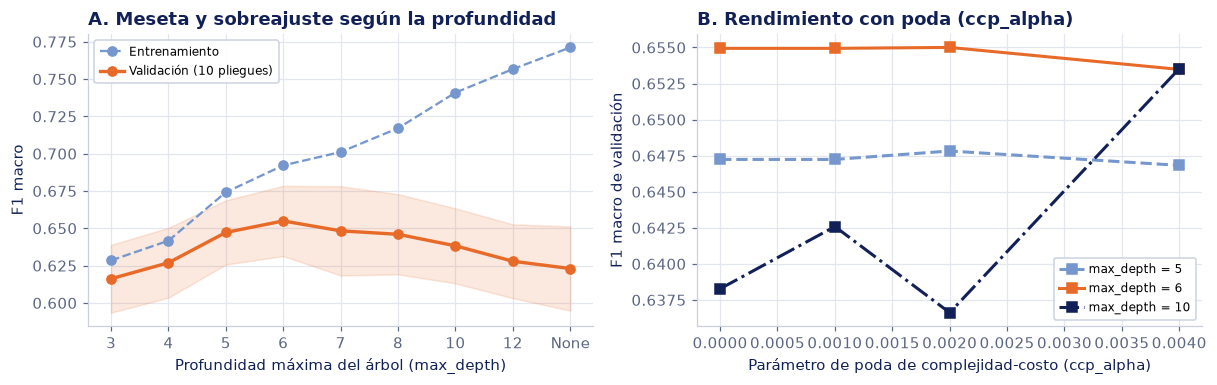

In [12]:
# Gráfica de F1 macro contra max_depth y ccp_alpha
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.6))

# Panel 1: Curva contra max_depth
filtro_md = (
    (res_arbol["param_clf__criterion"] == busqueda_arbol.best_params_["clf__criterion"]) &
    (res_arbol["param_clf__min_samples_leaf"] == busqueda_arbol.best_params_["clf__min_samples_leaf"]) &
    (res_arbol["param_clf__ccp_alpha"] == 0.0) &
    (res_arbol["param_clf__class_weight"] == busqueda_arbol.best_params_["clf__class_weight"])
)
sub_md = res_arbol[filtro_md].copy()
etiquetas_md = [str(v) if v is not None else "None" for v in sub_md["param_clf__max_depth"]]
x_md = np.arange(len(etiquetas_md))

axes[0].plot(x_md, sub_md["mean_train_score"], marker="o", linestyle="--", color=AZUL, label="Entrenamiento")
axes[0].plot(x_md, sub_md["mean_test_score"], marker="o", linewidth=2.2, color=NARANJA, label="Validación (10 pliegues)")
axes[0].fill_between(
    x_md,
    sub_md["mean_test_score"] - sub_md["std_test_score"],
    sub_md["mean_test_score"] + sub_md["std_test_score"],
    color=NARANJA, alpha=0.15
)
axes[0].set_xticks(x_md, etiquetas_md)
axes[0].set_xlabel("Profundidad máxima del árbol (max_depth)")
axes[0].set_ylabel("F1 macro")
axes[0].set_title("A. Meseta y sobreajuste según la profundidad")
axes[0].legend(
    loc="upper left",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.45,
    handletextpad=0.4,
)

# Panel 2: Efecto de la poda para distintas profundidades
for prof, color_p, estilo in [(5, AZUL, "--"), (6, NARANJA, "-"), (10, AZUL_OSCURO, "-.")]:
    f_ccp = (
        (res_arbol["param_clf__criterion"] == busqueda_arbol.best_params_["clf__criterion"]) &
        (res_arbol["param_clf__min_samples_leaf"] == busqueda_arbol.best_params_["clf__min_samples_leaf"]) &
        (res_arbol["param_clf__max_depth"] == prof) &
        (res_arbol["param_clf__class_weight"] == busqueda_arbol.best_params_["clf__class_weight"])
    )
    sub_ccp = res_arbol[f_ccp].sort_values("param_clf__ccp_alpha")
    axes[1].plot(
        sub_ccp["param_clf__ccp_alpha"], sub_ccp["mean_test_score"],
        marker="s", linewidth=2, color=color_p, linestyle=estilo, label=f"max_depth = {prof}"
    )

axes[1].set_xlabel("Parámetro de poda de complejidad-costo (ccp_alpha)")
axes[1].set_ylabel("F1 macro de validación")
axes[1].set_title("B. Rendimiento con poda (ccp_alpha)")
axes[1].legend(
    loc="lower right",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.45,
    handletextpad=0.4,
)

plt.tight_layout()
plt.show()

**Lectura.** El comportamiento del árbol de decisión muestra el compromiso entre capacidad y sobreajuste que ya hemos visto en clase:

1. En el **Panel A** (con $\alpha = 0$), el F1 macro de validación sube rápidamente de `max_depth = 3` (0.629) hasta alcanzar su meseta entre `max_depth = 5` y `7` (~0.654–0.655). A partir de `max_depth = 8` y `None`, el F1 de entrenamiento sube hasta superar 0.77, pero el de validación cae a 0.622 porque las hojas profundas empiezan a memorizar combinaciones específicas de estudiantes, es decir, se sobreajusta.

2. En el **Panel B** se observa cómo la poda de complejidad-costo (`ccp_alpha = 0.002`) recorta las ramas débiles y permite que incluso un árbol profundo (`max_depth = 10`) converja exactamente a la misma meseta óptima (**0.6550**) que el árbol de profundidad 6 con criterio de entropía y pesos moderados.

---

### 4.2. Naive Bayes (`CategoricalNB`, `BernoulliNB` y `GaussianNB`)

Cuando probé inicialmente la versión por omisión de `GaussianNB` sobre los datos preprocesados con *one-hot encoding*, el resultado fue confuso ya que el F1 macro cayó a ~0.21, lo que es mucho peor que adivinar al azar.

##### ¿Por qué ocurrió esto?
Porque al expandir los 9 atributos nominales en más de 100 columnas binarias `0/1` (muchas de ellas con frecuencias menores al 2 %), `GaussianNB` ajusta una campana normal con varianza casi cero sobre cada columna. Aquí, basta con que un estudiante de validación tenga una categoría poco común para que la densidad gaussiana produzca un valor extremo y la probabilidad colapse hacia una sola clase.

En clase ya vimos cómo, cuando una tabla mezcla atributos nominales y numéricos o no cumple la normalidad, una alternativa es discretizar las variables continuas con `KBinsDiscretizer` y usar `CategoricalNB`, por este motivo, diseñamos una búsqueda de **78 configuraciones** que compara directamente las tres variantes de Naive Bayes (`CategoricalNB`, `BernoulliNB` y `GaussianNB`), cada una acoplada a su propio `ColumnTransformer` dentro del `Pipeline`:
- **`CategoricalNB` (64 configuraciones):** Codifica los nominales como enteros ordinales (`OrdinalEncoder`, reservando un código para categorías no vistas en prueba) y discretiza todas las variables numéricas continuas con `KBinsDiscretizer`, explorando el número de intervalos (`n_bins` : `[4, 5, 6, 8]`), la estrategia de corte (`["quantile", "uniform"]`) y el suavizado de Laplace/Lidstone (`alpha`: de `0.001` a `5.0`).

- **`BernoulliNB` (6 configuraciones):** Codifica los nominales con `OneHotEncoder` y discretiza las numéricas en indicadores binarios por cuantiles (`encode="onehot-dense"`), variando `alpha` de `0.01` a `5.0`.

- **`GaussianNB` (8 configuraciones):** Agrupa las categorías nominales raras (`min_frequency=20`) para evitar varianzas nulas, estandariza las numéricas con `StandardScaler` y explora el suavizado de varianza (`var_smoothing`: de $10^{-9}$ a `0.5`).

Ejecutamos las tres variantes de Naive Bayes.

In [13]:
pre_nb_cat = ColumnTransformer([
    ("nom", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=99, encoded_missing_value=99), NOMINALES_MULTICLASE),
    ("num", KBinsDiscretizer(n_bins=6, encode="ordinal", strategy="quantile"), NUMERICOS_TOTAL),
    ("bin", "passthrough", BINARIOS_TOTAL),
])

pre_nb_bern = ColumnTransformer([
    ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINALES_MULTICLASE),
    ("num", KBinsDiscretizer(n_bins=5, encode="onehot-dense", strategy="quantile"), NUMERICOS_TOTAL),
    ("bin", "passthrough", BINARIOS_TOTAL),
])

pre_nb_gauss = ColumnTransformer([
    ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), NOMINALES_MULTICLASE),
    ("num", StandardScaler(), NUMERICOS_TOTAL),
    ("bin", "passthrough", BINARIOS_TOTAL),
])

pipe_nb = Pipeline([
    ("indicadores", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_nb_cat),
    ("clf", CategoricalNB(min_categories=105)),
])

rejilla_nb = [
    {
        "prep": [pre_nb_cat],
        "prep__num__n_bins": [4, 5, 6, 8],
        "prep__num__strategy": ["quantile", "uniform"],
        "clf": [CategoricalNB(min_categories=105)],
        "clf__alpha": [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0],
    },
    {
        "prep": [pre_nb_bern],
        "clf": [BernoulliNB()],
        "clf__alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0],
    },
    {
        "prep": [pre_nb_gauss],
        "clf": [GaussianNB()],
        "clf__var_smoothing": [1e-9, 1e-5, 1e-3, 1e-2, 0.05, 0.1, 0.2, 0.5],
    },
]

inicio = time.perf_counter()
busqueda_nb = GridSearchCV(
    pipe_nb, rejilla_nb, cv=pliegues, scoring="f1_macro", n_jobs=-1, return_train_score=True
).fit(X, y)
tiempo_nb = time.perf_counter() - inicio

res_nb = pd.DataFrame(busqueda_nb.cv_results_)
n_configs_nb = len(res_nb)

print(f"Configuraciones evaluadas : {n_configs_nb} (en {tiempo_nb:.1f} s)")
print(f"Mejor F1 macro (VC 10)    : {busqueda_nb.best_score_:.4f}")
print(f"Mejor variante            : {type(busqueda_nb.best_params_['clf']).__name__}")
print(f"Mejor suavizado (alpha)   : {busqueda_nb.best_params_['clf__alpha']}")
print(f"Discretización óptima     : {busqueda_nb.best_params_['prep__num__n_bins']} intervalos ({busqueda_nb.best_params_['prep__num__strategy']})")

Configuraciones evaluadas : 78 (en 5.4 s)
Mejor F1 macro (VC 10)    : 0.6583
Mejor variante            : CategoricalNB
Mejor suavizado (alpha)   : 0.01
Discretización óptima     : 6 intervalos (quantile)


Observemos cómo cambia el F1 Macro para cada variante con respecto al parámetro de suavizado, así como el desempeño al elegir la variante adecuada.

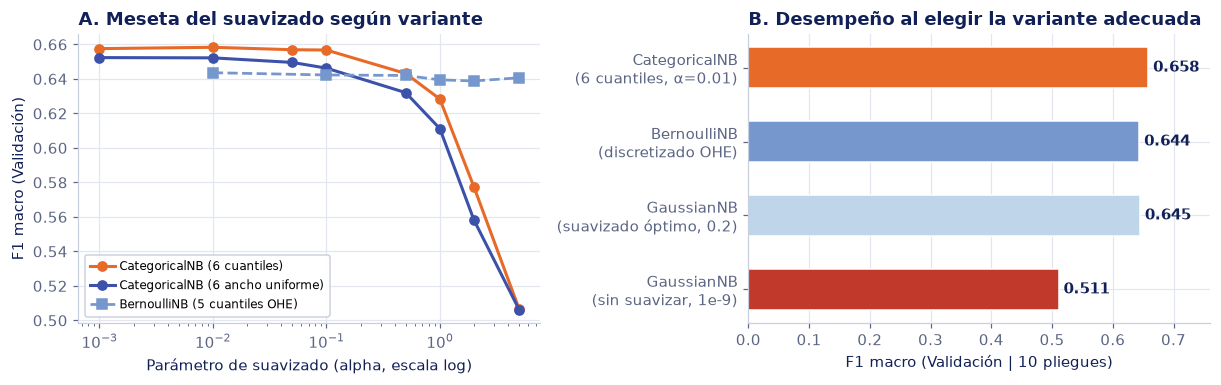

In [14]:
# Gráfica de comparación de variantes y curva de suavizado en CategoricalNB
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.6))

# Panel 1: Curva de alpha en CategoricalNB y BernoulliNB
es_cat = res_nb["param_clf"].map(lambda c: type(c).__name__ == "CategoricalNB")
es_bern = res_nb["param_clf"].map(lambda c: type(c).__name__ == "BernoulliNB")
es_gauss = res_nb["param_clf"].map(lambda c: type(c).__name__ == "GaussianNB")

for strat, color_s, etiq in [("quantile", NARANJA, "CategoricalNB (6 cuantiles)"), ("uniform", AZUL_MEDIO, "CategoricalNB (6 ancho uniforme)")]:
    sub_c = res_nb[es_cat & (res_nb["param_prep__num__n_bins"] == 6) & (res_nb["param_prep__num__strategy"] == strat)].sort_values("param_clf__alpha")
    axes[0].plot(sub_c["param_clf__alpha"], sub_c["mean_test_score"], marker="o", linewidth=2, color=color_s, label=etiq)

sub_b = res_nb[es_bern].sort_values("param_clf__alpha")
axes[0].plot(sub_b["param_clf__alpha"], sub_b["mean_test_score"], marker="s", linestyle="--", linewidth=1.8, color=AZUL, label="BernoulliNB (5 cuantiles OHE)")

axes[0].set_xscale("log")
axes[0].set_xlabel("Parámetro de suavizado (alpha, escala log)")
axes[0].set_ylabel("F1 macro (Validación)")
axes[0].set_title("A. Meseta del suavizado según variante")
axes[0].legend(
    loc="lower left",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.45,
    handletextpad=0.4,
)

# Panel 2: Comparación del mejor resultado de cada variante de Naive Bayes
mejores_variantes = pd.Series({
    "GaussianNB\n(sin suavizar, 1e-9)": res_nb[es_gauss & (res_nb["param_clf__var_smoothing"] == 1e-9)]["mean_test_score"].iloc[0],
    "GaussianNB\n(suavizado óptimo, 0.2)": res_nb[es_gauss]["mean_test_score"].max(),
    "BernoulliNB\n(discretizado OHE)": res_nb[es_bern]["mean_test_score"].max(),
    "CategoricalNB\n(6 cuantiles, α=0.01)": res_nb[es_cat]["mean_test_score"].max(),
})

colores_nb = [ROJO, AZUL_CLARO, AZUL, NARANJA]
barras_nb = axes[1].barh(mejores_variantes.index, mejores_variantes.values, color=colores_nb, height=0.55, edgecolor="white")
for b, val in zip(barras_nb, mejores_variantes.values):
    axes[1].text(val + 0.008, b.get_y() + b.get_height() / 2, f"{val:.3f}", va="center", fontweight="bold", color=AZUL_OSCURO)

axes[1].set_xlim(0, 0.76)
axes[1].set_xlabel("F1 macro (Validación | 10 pliegues)")
axes[1].set_title("B. Desempeño al elegir la variante adecuada")

plt.tight_layout()
plt.show()

**Lectura.** El contraste entre las variantes de Naive Bayes confirma que el preprocesamiento debe adaptarse al modelo:

1. En el **Panel A**, al discretizar las variables continuas en 6 cuantiles con `KBinsDiscretizer` y aplicar `CategoricalNB`, el modelo alcanza una **meseta muy estable entre $\alpha = 0.001$ y $\alpha = 0.1$**, logrando su máximo en **$\alpha = 0.01$ con un F1 macro de 0.6583** (por encima del mejor árbol de decisión y de kNN, como se verá en la subsección posterior). Cuando $\alpha$ crece más allá de 1.0, el suavizado excesivo aplana las probabilidades hacia la distribución uniforme y el F1 empieza a descender. Por su parte, `BernoulliNB` mantiene el F1 relativamente estable, por encima de 0.65.

2. En el **Panel B**, `GaussianNB` con su suavizado por omisión ($10^{-9}$) obtiene el peor F1 macro (**0.511**) debido a las columnas binarias de baja frecuencia. Aumentar agresivamente `var_smoothing` a `0.2` lo rescata hasta **0.645** y lo acerca a las variantes discretas.


---

### 4.3. k Vecinos más Cercanos (`KNeighborsClassifier`)

Al aplicar *one-hot encoding* a los 9 atributos nominales (incluso agrupando las categorías con menos de 15 alumnos), el espacio de características se expande a más de 120 columnas. Cuando probamos KNN directamente sobre todas esas columnas estandarizadas, el F1 macro apenas llegaba a ~0.55–0.61. Sabemos que KNN suma las diferencias coordenada por coordenada; por lo que, si hay decenas de indicadores binarios de ocupaciones o nacionalidades poco informativas, dos estudiantes con el mismo aprovechamiento académico parecerán "lejanos" solo por diferir en el oficio de sus padres.

Por ello, en el `Pipeline` de kNN incluimos un paso de selección de características (`SelectKBest(f_classif)`) antes del `StandardScaler` final y del clasificador, e integramos el número de atributos seleccionados dentro de una búsqueda de **120 configuraciones**:

- **Atributos conservados (`sel__k`):** `[25, 40, "all"]` (para medir directamente cuánto gana KNN al filtrar columnas ruidosas vs. si usamos `"all"`).

- **Número de vecinos (`n_neighbors`):** `[3, 5, 7, 9, 13, 17, 21, 25, 31, 41]`.
- **Ponderación del voto (`weights`):** `["uniform", "distance"]`.
- **Métrica de distancia (`p`):** `[1, 2]` ($p = 1$ para distancia Manhattan $L_1$ y $p = 2$ para distancia Euclidiana $L_2$).

Corremos las 120 configuraciones de KNN.

In [15]:
pre_knn = ColumnTransformer([
    ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=15, sparse_output=False), NOMINALES_MULTICLASE),
    ("num", StandardScaler(), NUMERICOS_TOTAL),
    ("bin", "passthrough", BINARIOS_TOTAL),
])

pipe_knn = Pipeline([
    ("indicadores", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_knn),
    ("sel", SelectKBest(f_classif, k=40)),
    ("esc", StandardScaler()),
    ("clf", KNeighborsClassifier()),
])

rejilla_knn = {
    "sel__k": [25, 40, "all"],
    "clf__n_neighbors": [3, 5, 7, 9, 13, 17, 21, 25, 31, 41],
    "clf__weights": ["uniform", "distance"],
    "clf__p": [1, 2],
}

inicio = time.perf_counter()
busqueda_knn = GridSearchCV(
    pipe_knn, rejilla_knn, cv=pliegues, scoring="f1_macro", n_jobs=-1, return_train_score=True
).fit(X, y)
tiempo_knn = time.perf_counter() - inicio

res_knn = pd.DataFrame(busqueda_knn.cv_results_)
n_configs_knn = len(res_knn)

print(f"Configuraciones evaluadas : {n_configs_knn} (en {tiempo_knn:.1f} s)")
print(f"Mejor F1 macro (VC 10)    : {busqueda_knn.best_score_:.4f}")
print("Mejores hiperparámetros   :")
for k, v in busqueda_knn.best_params_.items():
    print(f"  {k}: {v}")

Configuraciones evaluadas : 120 (en 38.1 s)
Mejor F1 macro (VC 10)    : 0.6514
Mejores hiperparámetros   :
  clf__n_neighbors: 13
  clf__p: 1
  clf__weights: uniform
  sel__k: 40


Graficamos cómo cambia el F1 Macro con respecto al número de vecinos, para cada tipo de distancia. Así mismo, observamos el impacto de las variables irrelevantes en la distancia.

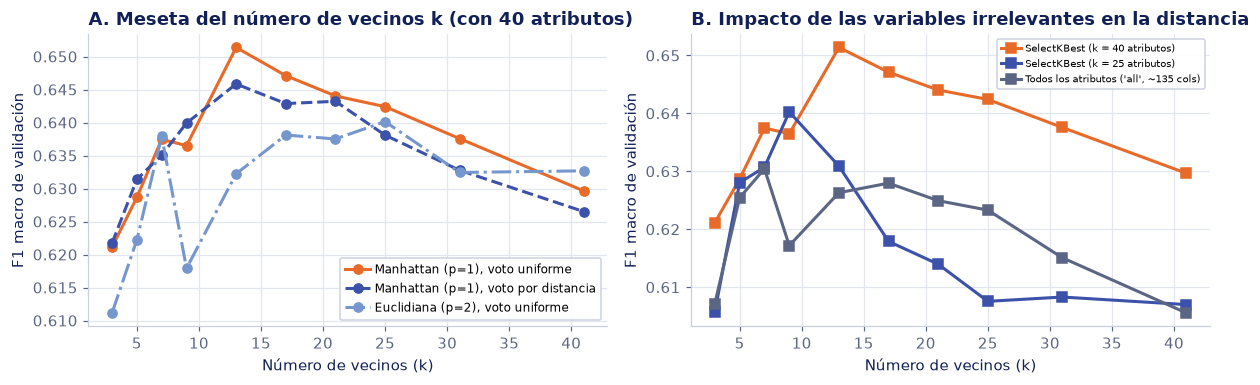

In [16]:
# Gráfica de F1 macro contra k (n_neighbors)
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.6))

# Panel 1: Curva contra k para p=1 (Manhattan) vs p=2 (Euclidiana) con sel__k=40
for dist_p, w_tipo, color_l, estilo, etiq in [
    (1, "uniform", NARANJA, "-", "Manhattan (p=1), voto uniforme"),
    (1, "distance", AZUL_MEDIO, "--", "Manhattan (p=1), voto por distancia"),
    (2, "uniform", AZUL, "-.", "Euclidiana (p=2), voto uniforme"),
]:
    f_k = (
        (res_knn["param_sel__k"] == 40) &
        (res_knn["param_clf__p"] == dist_p) &
        (res_knn["param_clf__weights"] == w_tipo)
    )
    sub_k = res_knn[f_k].sort_values("param_clf__n_neighbors")
    axes[0].plot(
        sub_k["param_clf__n_neighbors"], sub_k["mean_test_score"],
        marker="o", linewidth=2, color=color_l, linestyle=estilo, label=etiq
    )

axes[0].set_xlabel("Número de vecinos (k)")
axes[0].set_ylabel("F1 macro de validación")
axes[0].set_title("A. Meseta del número de vecinos k (con 40 atributos)")
axes[0].legend(
    loc="lower right",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.45,
    handletextpad=0.4,
)

# Panel 2: Efecto de filtrar variables irrelevantes
for k_sel, color_s, etiq_s in [
    (40, NARANJA, "SelectKBest (k = 40 atributos)"),
    (25, AZUL_MEDIO, "SelectKBest (k = 25 atributos)"),
    ("all", GRIS, "Todos los atributos ('all', ~135 cols)"),
]:
    f_sel = (
        (res_knn["param_sel__k"] == k_sel) &
        (res_knn["param_clf__p"] == 1) &
        (res_knn["param_clf__weights"] == "uniform")
    )
    sub_s = res_knn[f_sel].sort_values("param_clf__n_neighbors")
    axes[1].plot(
        sub_s["param_clf__n_neighbors"], sub_s["mean_test_score"],
        marker="s", linewidth=2, color=color_s, label=etiq_s
    )

axes[1].set_xlabel("Número de vecinos (k)")
axes[1].set_ylabel("F1 macro de validación")
axes[1].set_title("B. Impacto de las variables irrelevantes en la distancia")
axes[1].legend(
    loc="upper right",
    fontsize=6.5,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.45,
    handletextpad=0.4,
)

plt.tight_layout()
plt.show()

**Lectura.** Las gráficas de kNN nos muestran dos fenómenos del aprendizaje basado en instancias:

1. En el **Panel A**, con $k$ pequeños ($k = 3$ o $5$) las fronteras son ruidosas y el F1 macro ronda 0.625. Al aumentar el tamaño del vecindario, el desempeño sube y forma una meseta (no tan clara) entre $k = 13$ y $k = 25$ vecinos, alcanzando su máximo en **$k = 13$ con distancia Manhattan ($p = 1$) y voto uniforme (F1 macro = 0.6514)**.
Además, la distancia Manhattan ($p = 1$, líneas naranja y azul oscuro) supera de forma consistente a la Euclidiana ($p = 2$) en todos los valores de $k$, porque al trabajar con una mezcla de variables continuas e indicadores `0/1`, sumar diferencias absolutas evita que una sola discrepancia grande eleve la distancia al cuadrado.

2. En el **Panel B** se confirma por qué kNN sufría al usar todas las columnas codificadas (`"all"`, línea gris): las más de 90 columnas *one-hot* de baja relevancia disminuyen el F1 macro en ~3 puntos porcentuales a lo largo de toda la curva. Conservar los 40 atributos con mayor estadístico $F$ (`SelectKBest`) limpia la métrica de distancia. Conservar los 25 atributos con mayor estadístico es casi tan malo como conservarlos todos.

---

### 4.4. Máquinas de Soporte Vectorial (`SVC`)

Para el SVM utilizamos `OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist")` en las variables nominales y `StandardScaler()` en las numéricas, de modo que todas las variables continuas tengan media 0 y varianza 1 antes de calcular productos punto o distancias en el kernel.

Evaluamos **69 configuraciones** divididas entre los dos kernels principales vistos en clase:

- **Kernel Gaussiano (`rbf`, 60 configuraciones):** Cruza $C \in \{0.3, 0.7, 1.2, 2.0, 3.0\}$, el ancho inverso de campana $\gamma \in \{\text{"scale"}, 0.005, 0.01, 0.02\}$ y los tres esquemas de pesos por clase (`None`, `"balanced"`, `PESOS_SUAVES`).

- **Kernel Lineal (`linear`, 9 configuraciones):** Cruza $C \in \{0.02, 0.05, 0.1\}$ con los tres esquemas de pesos por clase.

In [17]:
pre_svm = ColumnTransformer([
    ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False), NOMINALES_MULTICLASE),
    ("num", StandardScaler(), NUMERICOS_TOTAL),
    ("bin", "passthrough", BINARIOS_TOTAL),
])

pipe_svm = Pipeline([
    ("indicadores", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_svm),
    ("clf", SVC(cache_size=500, random_state=SEMILLA)),
])

rejilla_svm = [
    {
        "clf__kernel": ["rbf"],
        "clf__C": [0.3, 0.7, 1.2, 2.0, 3.0],
        "clf__gamma": ["scale", 0.005, 0.01, 0.02],
        "clf__class_weight": [None, "balanced", PESOS_SUAVES],
    },
    {
        "clf__kernel": ["linear"],
        "clf__C": [0.02, 0.05, 0.1],
        "clf__class_weight": [None, "balanced", PESOS_SUAVES],
    },
]

inicio = time.perf_counter()
busqueda_svm = GridSearchCV(
    pipe_svm, rejilla_svm, cv=pliegues, scoring="f1_macro", n_jobs=-1, return_train_score=False
).fit(X, y)
tiempo_svm = time.perf_counter() - inicio

res_svm = pd.DataFrame(busqueda_svm.cv_results_)
n_configs_svm = len(res_svm)

print(f"Configuraciones evaluadas : {n_configs_svm} (en {tiempo_svm:.1f} s)")
print(f"Mejor F1 macro (VC 10)    : {busqueda_svm.best_score_:.4f}")
print("Mejores hiperparámetros   :")
for k, v in busqueda_svm.best_params_.items():
    print(f"  {k}: {v}")

Configuraciones evaluadas : 69 (en 65.9 s)
Mejor F1 macro (VC 10)    : 0.6900
Mejores hiperparámetros   :
  clf__C: 1.2
  clf__class_weight: {'Dropout': 0.95, 'Enrolled': 1.6, 'Graduate': 0.75}
  clf__gamma: scale
  clf__kernel: rbf


Resumimos primero en dos tablas los valores de F1 Macro obtenidos con el kernel RBF al cruzar el parámetro $C$ con cada valor de $\gamma$ (Panel A) y con los tres esquemas de pesos por clase (Panel B).

In [18]:
es_rbf = res_svm["param_clf__kernel"] == "rbf"
es_suave_svm = res_svm["param_clf__class_weight"].map(lambda w: isinstance(w, dict))

# Tabla 1 (Panel A): F1 macro según C y gamma (con pesos moderados)
tabla_gamma_svm = (
    res_svm[es_rbf & es_suave_svm]
    .pivot(index="param_clf__gamma", columns="param_clf__C", values="mean_test_score")
    .round(4)
)
tabla_gamma_svm.index.name = "gamma"
tabla_gamma_svm.columns.name = "C"

# Tabla 2 (Panel B): F1 macro según C y esquema de pesos (con gamma = 'scale')
sub_pesos_svm = res_svm[es_rbf & (res_svm["param_clf__gamma"] == "scale")].copy()
sub_pesos_svm["Esquema de pesos"] = sub_pesos_svm["param_clf__class_weight"].map(
    lambda w: "Pesos moderados" if isinstance(w, dict) else ("Balanceado ('balanced')" if w == "balanced" else "Sin pesos (None)")
)
tabla_pesos_svm = (
    sub_pesos_svm
    .pivot(index="Esquema de pesos", columns="param_clf__C", values="mean_test_score")
    .reindex(["Pesos moderados", "Balanceado ('balanced')", "Sin pesos (None)"])
    .round(4)
)
tabla_pesos_svm.columns.name = "C"

print("Panel A — F1 macro en validación por valor de gamma y C (RBF con pesos moderados):")
display(tabla_gamma_svm)
print("\nPanel B — F1 macro en validación por esquema de pesos y C (RBF con gamma = 'scale'):")
display(tabla_pesos_svm)

Panel A — F1 macro en validación por valor de gamma y C (RBF con pesos moderados):


C,0.3,0.7,1.2,2.0,3.0
gamma,,,,,
0.005,0.6399,0.6500,0.6695,0.6818,0.6851
0.01,0.6460,0.6689,0.6796,0.6878,0.6866
0.02,0.6517,0.6780,0.6862,0.6850,0.6804
scale,0.6556,0.6805,0.6900,0.6849,0.6780



Panel B — F1 macro en validación por esquema de pesos y C (RBF con gamma = 'scale'):


C,0.3,0.7,1.2,2.0,3.0
Esquema de pesos,,,,,
Pesos moderados,0.6556,0.6805,0.6900,0.6849,0.6780
Balanceado ('balanced'),0.6599,0.6790,0.6794,0.6778,0.6711
Sin pesos (None),0.6006,0.6356,0.6481,0.6584,0.6580


Graficamos cómo cambia el F1 Macro con respecto al parámetro de regularización $C$ para cada valor de $\gamma$, así como el efecto de los tres esquemas de pesos por clase.

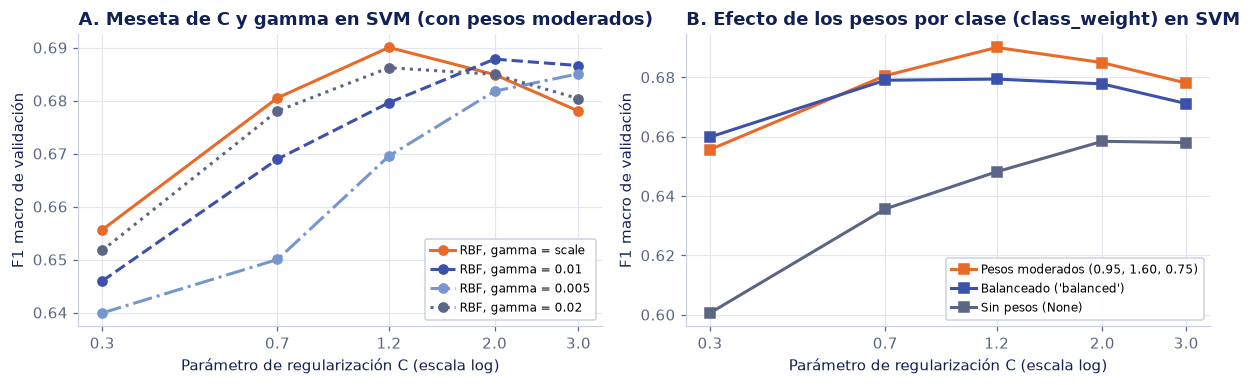

In [19]:
# Gráfica de F1 macro contra C para distintos valores de gamma y comparación de class_weight
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.6))
valores_c = [0.3, 0.7, 1.2, 2.0, 3.0]

# Panel 1: Curvas de C según gamma
for g_val, color_g, estilo_g in [
    ("scale", NARANJA, "-"),
    (0.01, AZUL_MEDIO, "--"),
    (0.005, AZUL, "-."),
    (0.02, GRIS, ":"),
]:
    sub_g = res_svm[es_rbf & es_suave_svm & (res_svm["param_clf__gamma"] == g_val)].sort_values("param_clf__C")
    axes[0].plot(
        sub_g["param_clf__C"], sub_g["mean_test_score"],
        marker="o", linewidth=2, color=color_g, linestyle=estilo_g, label=f"RBF, gamma = {g_val}"
    )

axes[0].set_xscale("log")
axes[0].set_xticks(valores_c, [str(v) for v in valores_c])
axes[0].minorticks_off()
axes[0].set_xlabel("Parámetro de regularización C (escala log)")
axes[0].set_ylabel("F1 macro de validación")
axes[0].set_title("A. Meseta de C y gamma en SVM (con pesos moderados)")
axes[0].legend(
    loc="lower right",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.45,
    handletextpad=0.4,
)

# Panel 2: Comparación de los tres esquemas
for nom_w, filtro_w, col_w in [
    ("Pesos moderados (0.95, 1.60, 0.75)", es_suave_svm, NARANJA),
    ("Balanceado ('balanced')", res_svm["param_clf__class_weight"] == "balanced", AZUL_MEDIO),
    ("Sin pesos (None)", res_svm["param_clf__class_weight"].isna(), GRIS),
]:
    sub_w = res_svm[es_rbf & (res_svm["param_clf__gamma"] == "scale") & filtro_w].sort_values("param_clf__C")
    axes[1].plot(
        sub_w["param_clf__C"], sub_w["mean_test_score"],
        marker="s", linewidth=2, color=col_w, label=nom_w
    )

axes[1].set_xscale("log")
axes[1].set_xticks(valores_c, [str(v) for v in valores_c])
axes[1].minorticks_off()
axes[1].set_xlabel("Parámetro de regularización C (escala log)")
axes[1].set_ylabel("F1 macro de validación")
axes[1].set_title("B. Efecto de los pesos por clase (class_weight) en SVM")
axes[1].legend(
    loc="lower right",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.45,
    handletextpad=0.4,
)

plt.tight_layout()
plt.show()

**Lectura.** Con las tablas y las gráficas podemos ver cómo se comporta el SVM:

1. **Panel A:** El parámetro $C$ controla qué tanto castigamos los errores de clasificación y $\gamma$ controla qué tan "cerrada" es la frontera alrededor de los estudiantes de cada clase.  
Con $\gamma = \text{"scale"}$ (línea naranja) y $\gamma = 0.02$ (línea punteada gris), el F1 macro sube rápidamente desde $C = 0.3$ (`0.6556` y `0.6517`, respectivamente) hasta alcanzar su punto más alto en **$C = 1.2$ con $\gamma = \text{"scale"}$ (`0.6900`)**; si aumentamos más el castigo ($C = 2.0$ y $3.0$), el modelo se ajusta demasiado a los casos de entrenamiento y el puntaje empieza a bajar (`0.6849` y `0.6780`).  
En cambio, con valores de $\gamma$ más pequeños (`0.01` y `0.005`, líneas azules), la frontera es más suave y necesita un $C$ mayor (`2.0` o `3.0`) para terminar de subir y alcanzar su meseta (`0.6878` y `0.6851`).

2. **Panel B:** Cuando no aplicamos pesos (línea gris), el modelo le da prioridad a las clases mayoritarias y se queda rezagado entre `0.6006` ($C = 0.3$) y `0.6584` ($C = 2.0$).  
Al usar el ajuste automático `"balanced"` (línea azul), el F1 macro sube a una meseta de `0.6790–0.6794` entre $C = 0.7$ y $1.2$.  
Finalmente, nuestros **pesos moderados** (línea naranja) logran el mejor equilibrio a partir de $C = 0.7$, ya que supera a `"balanced"` por un punto porcentual en el óptimo de $C = 1.2$ (`0.6900` frente a `0.6794`).

---

### 4.5. Regresión Logística (`LogisticRegression`)

Me parece pertinente comentar que en una primera prueba entrené la Regresión Logística únicamente estandarizando las variables numéricas (`StandardScaler`) y codificando las nominales con `OneHotEncoder(min_frequency=8, handle_unknown="infrequent_if_exist")`. El resultado fue bueno (~0.684), pero se quedaba un paso por detrás del SVM con kernel `rbf` (0.6900). De ahí surgió la pregunta: ¿por qué el SVM tiene ventaja sobre la Regresión Logística y hay forma de mejorar el resultado sin cambiar de clasificador?

Investigando un poco pude entender que, en una Regresión Logística tradicional, cada columna numérica recibe un solo peso (coeficiente). Eso obliga al modelo a asumir que cualquier cambio vale siempre lo mismo a lo largo de toda la escala: por ejemplo, asume que pasar de **0 a 1 materia reprobada** cambia el riesgo de desertar en la misma proporción que pasar de **4 a 5 materias reprobadas**, o que tener **18 frente a 20 años** pesa igual que tener **23 frente a 25 años**. Sin embargo, en la práctica esto no ocurre así, porque existen *escalones* muy marcados: reprobar la primera materia o ingresar después de los 23 años cambia mucho más el pronóstico del alumno que sumar otra materia reprobada cuando ya reprobó cuatro.

##### ¿Cómo se resolvió desde el preprocesamiento?
Además de mantener las variables numéricas estandarizadas, agregamos en el `ColumnTransformer` una rama con `KBinsDiscretizer(n_bins=5, encode="onehot-dense", strategy="quantile")` para las 9 variables continuas y de conteo más importantes (edad, notas de admisión y de primer semestre, unidades inscritas, evaluadas, aprobadas, reprobadas y tasa de aprobación). Es decir, se parte cada variable en 5 rangos (cuantiles) (por ejemplo, calificaciones muy bajas, bajas, medias, altas y muy altas) y crea una columna indicadora `0/1` para cada rango. De este modo, la Regresión Logística puede asignarle un peso distinto a cada escalón y capturar esos cambios bruscos igual de bien que el SVM pero manteniendo sus ventajas propias.

Con este preprocesamiento evaluamos **60 configuraciones** que exploran:
- **Tipo de regularización (`penalty`):** Regularización cuadrática $L_2$ (`"l2"`, 39 configuraciones, que encoge los pesos de forma suave) y regularización absoluta $L_1$ (`"l1"`, 21 configuraciones, que descarta variables llevando sus pesos exactamente a cero).
- **Fuerza de regularización inversa (`C`):** Desde un castigo muy fuerte a los pesos ($C = 0.005$) hasta uno muy débil ($C = 5.0$).
- **Pesos por clase (`class_weight`):** `[None, "balanced", PESOS_SUAVES]`.

Ejecutamos las 60 configuraciones de Regresión Logística.

In [20]:
COLS_BINS = [
    "Age at enrollment", "Admission grade", "Previous qualification (grade)",
    "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
    "tasa_aprobacion_1s", "reprobadas_1s"
]

pre_log = ColumnTransformer([
    ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=8, sparse_output=False), NOMINALES_MULTICLASE),
    ("num", StandardScaler(), NUMERICOS_TOTAL),
    ("bins", KBinsDiscretizer(n_bins=5, encode="onehot-dense", strategy="quantile"), COLS_BINS),
    ("bin", "passthrough", BINARIOS_TOTAL),
])

pipe_log = Pipeline([
    ("indicadores", FunctionTransformer(agregar_indicadores_1er_semestre)),
    ("prep", pre_log),
    ("clf", LogisticRegression(max_iter=800, random_state=SEMILLA)),
])

rejilla_log = [
    {
        "clf__penalty": ["l2"],
        "clf__solver": ["lbfgs"],
        "clf__C": [0.005, 0.01, 0.02, 0.05, 0.08, 0.1, 0.15, 0.2, 0.3, 0.5, 1.0, 2.0, 5.0],
        "clf__class_weight": [None, "balanced", PESOS_SUAVES],
    },
    {
        "clf__penalty": ["l1"],
        "clf__solver": ["saga"],
        "clf__max_iter": [300],
        "clf__C": [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0],
        "clf__class_weight": [None, "balanced", PESOS_SUAVES],
    },
]

inicio = time.perf_counter()
busqueda_log = GridSearchCV(
    pipe_log, rejilla_log, cv=pliegues, scoring="f1_macro", n_jobs=-1, return_train_score=False
).fit(X, y)
tiempo_log = time.perf_counter() - inicio

res_log = pd.DataFrame(busqueda_log.cv_results_)
n_configs_log = len(res_log)

print(f"Configuraciones evaluadas : {n_configs_log} (en {tiempo_log:.1f} s)")
print(f"Mejor F1 macro (VC 10)    : {busqueda_log.best_score_:.4f}")
print("Mejores hiperparámetros   :")
for k, v in busqueda_log.best_params_.items():
    print(f"  {k}: {v}")

Configuraciones evaluadas : 60 (en 82.5 s)
Mejor F1 macro (VC 10)    : 0.6938
Mejores hiperparámetros   :
  clf__C: 0.3
  clf__class_weight: {'Dropout': 0.95, 'Enrolled': 1.6, 'Graduate': 0.75}
  clf__penalty: l2
  clf__solver: lbfgs


Antes de graficar, mostramos en dos tablas los valores de F1 Macro para las curvas de ambos paneles: primero comparando las regularizaciones $L_2$ y $L_1$ (con pesos moderados), y después comparando los tres esquemas de pesos por clase (con regularización $L_2$).

In [21]:
es_l2 = res_log["param_clf__penalty"] == "l2"
es_l1 = res_log["param_clf__penalty"] == "l1"
es_suave_log = res_log["param_clf__class_weight"].map(lambda w: isinstance(w, dict))

# Tabla 1 (Panel A): F1 macro según tipo de regularización (L2 vs L1, con pesos moderados)
tabla_penalidad_log = (
    res_log[es_suave_log]
    .pivot(index="param_clf__penalty", columns="param_clf__C", values="mean_test_score")
    .reindex(["l2", "l1"])
    .round(4)
)
tabla_penalidad_log.index.name = "penalty"
tabla_penalidad_log.columns.name = "C"

# Tabla 2 (Panel B): F1 macro según esquema de pesos por clase (con regularización L2)
sub_pesos_log = res_log[es_l2].copy()
sub_pesos_log["Esquema de pesos"] = sub_pesos_log["param_clf__class_weight"].map(
    lambda w: "Pesos moderados" if isinstance(w, dict) else ("Balanceado ('balanced')" if w == "balanced" else "Sin pesos (None)")
)
tabla_pesos_log = (
    sub_pesos_log
    .pivot(index="Esquema de pesos", columns="param_clf__C", values="mean_test_score")
    .reindex(["Pesos moderados", "Balanceado ('balanced')", "Sin pesos (None)"])
    .round(4)
)
tabla_pesos_log.columns.name = "C"

print("Panel A — F1 macro en validación para L2 y L1 según C (con pesos moderados):")
display(tabla_penalidad_log)
print("\nPanel B — F1 macro en validación por esquema de pesos según C (con regularización L2):")
display(tabla_pesos_log)

Panel A — F1 macro en validación para L2 y L1 según C (con pesos moderados):


C,0.005,0.010,0.020,0.050,0.080,0.100,0.150,0.200,0.300,0.500,1.000,2.000,5.000
penalty,,,,,,,,,,,,,
l2,0.6558,0.6711,0.6821,0.6888,0.6887,0.6921,0.6895,0.6933,0.6938,0.6884,0.6871,0.6849,0.6834
l1,NaN,0.6316,0.6534,0.6667,NaN,0.6796,NaN,0.6829,NaN,0.6863,0.6888,NaN,NaN



Panel B — F1 macro en validación por esquema de pesos según C (con regularización L2):


C,0.005,0.010,0.020,0.050,0.080,0.100,0.150,0.200,0.300,0.500,1.000,2.000,5.000
Esquema de pesos,,,,,,,,,,,,,
Pesos moderados,0.6558,0.6711,0.6821,0.6888,0.6887,0.6921,0.6895,0.6933,0.6938,0.6884,0.6871,0.6849,0.6834
Balanceado ('balanced'),0.6580,0.6695,0.6747,0.6848,0.6836,0.6849,0.6887,0.6870,0.6857,0.6852,0.6818,0.6786,0.6780
Sin pesos (None),0.6064,0.6295,0.6435,0.6544,0.6560,0.6573,0.6590,0.6622,0.6630,0.6670,0.6685,0.6680,0.6694


Graficamos cómo cambia el F1 Macro con respecto al parámetro de regularización inversa $C$ para cada tipo de penalización ($L_2$ y $L_1$), así como el desempeño según el esquema de pesos por clase.

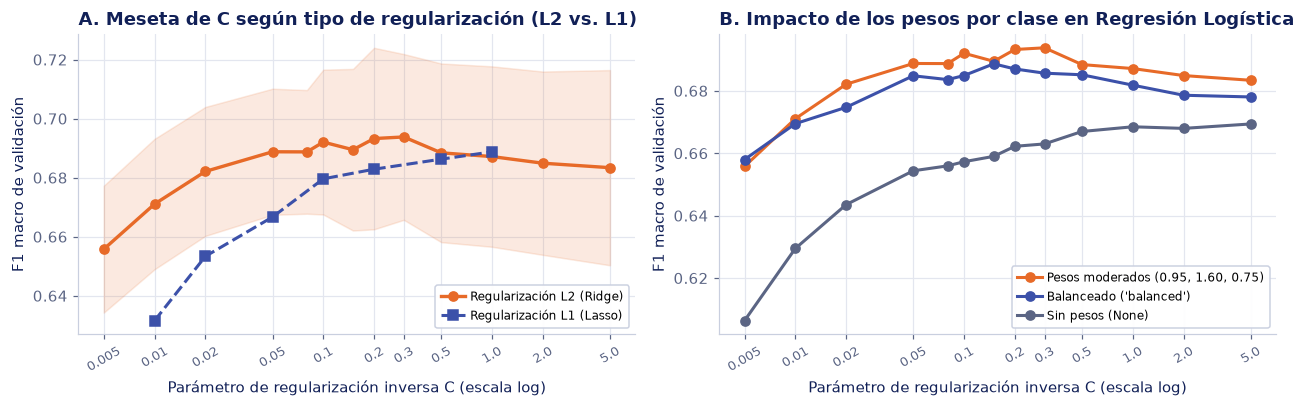

In [22]:
# Gráfica de F1 macro contra C
fig, axes = plt.subplots(1, 2, figsize=(11.8, 3.8))
valores_c_log = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0, 2.0, 5.0]
etiquetas_c_log = [str(v) for v in valores_c_log]

# Panel 1: Comparación de regularización L2 vs L1 (con pesos moderados)
sub_l2 = res_log[es_l2 & es_suave_log].sort_values("param_clf__C")
sub_l1 = res_log[es_l1 & es_suave_log].sort_values("param_clf__C")

axes[0].plot(sub_l2["param_clf__C"], sub_l2["mean_test_score"], marker="o", linewidth=2.2, color=NARANJA, label="Regularización L2 (Ridge)")
axes[0].fill_between(
    sub_l2["param_clf__C"],
    sub_l2["mean_test_score"] - sub_l2["std_test_score"],
    sub_l2["mean_test_score"] + sub_l2["std_test_score"],
    color=NARANJA, alpha=0.14
)
axes[0].plot(sub_l1["param_clf__C"], sub_l1["mean_test_score"], marker="s", linestyle="--", linewidth=2, color=AZUL_MEDIO, label="Regularización L1 (Lasso)")

axes[0].set_xscale("log")
axes[0].set_xticks(valores_c_log, etiquetas_c_log)
axes[0].tick_params(axis="x", labelsize=8.5, rotation=30)
axes[0].minorticks_off()
axes[0].set_xlabel("Parámetro de regularización inversa C (escala log)")
axes[0].set_ylabel("F1 macro de validación")
axes[0].set_title("A. Meseta de C según tipo de regularización (L2 vs. L1)")
axes[0].legend(
    loc="lower right",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.45,
    handletextpad=0.4,
)

# Panel 2: Comparación de class_weight en Regresión Logística L2
for nom_w, filtro_w, col_w in [
    ("Pesos moderados (0.95, 1.60, 0.75)", es_suave_log, NARANJA),
    ("Balanceado ('balanced')", res_log["param_clf__class_weight"] == "balanced", AZUL_MEDIO),
    ("Sin pesos (None)", res_log["param_clf__class_weight"].isna(), GRIS),
]:
    sub_w = res_log[es_l2 & filtro_w].sort_values("param_clf__C")
    axes[1].plot(
        sub_w["param_clf__C"], sub_w["mean_test_score"],
        marker="o", linewidth=2, color=col_w, label=nom_w
    )

axes[1].set_xscale("log")
axes[1].set_xticks(valores_c_log, etiquetas_c_log)
axes[1].tick_params(axis="x", labelsize=8.5, rotation=30)
axes[1].minorticks_off()
axes[1].set_xlabel("Parámetro de regularización inversa C (escala log)")
axes[1].set_ylabel("F1 macro de validación")
axes[1].set_title("B. Impacto de los pesos por clase en Regresión Logística")
axes[1].legend(
    loc="lower right",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.45,
    handletextpad=0.4,
)

plt.tight_layout()
plt.show()

**Lectura.** La Regresión Logística consigue el puntaje más alto de toda la práctica (**F1 macro = 0.6938**):

1. **Panel A:** En scikit-learn, $C$ es el *inverso* de la fuerza de regularización: un $C$ muy pequeño *frena* los pesos del modelo, mientras que un $C$ grande los deja crecer libremente.
   - Con **regularización $L_2$** (línea naranja), cuando $C = 0.005$ los pesos están demasiado frenados y el F1 macro es bajo (`0.6558`). Al darle más libertad al modelo, el puntaje sube rápido y forma una meseta entre $C = 0.05$ (`0.6888`) y $C = 0.5$ (`0.6884`), alcanzando su máximo en **$C = 0.3$ (`0.6938`)**. Al soltar más el freno ($C = 2.0$ o $5.0$), las categorías con pocos alumnos reciben pesos exagerados y el F1 baja ligeramente a `0.6849` y `0.6834`.
   - Con **regularización $L_1$** (línea azul punteada), como esta penalización vuelve exactamente cero muchos pesos cuando $C$ es pequeño, inicia más abajo en $C = 0.01$ (`0.6316`) y necesita llegar hasta $C = 0.5 \text{ – } 1.0$ para conservar suficientes variables y acercarse a la meseta (`0.6863` y `0.6888`).

2. **Panel B:** Al igual que en el SVM, dejar al modelo sin pesos (`Sin pesos (None)`, línea gris) afecta a la clase minoritaria `Enrolled`, quedándose entre `0.6064` ($C = 0.005$) y `0.6694` ($C = 5.0$). El ajuste automático `"balanced"` (línea azul) sube la curva hasta `0.6848–0.6887` en la zona central, pero los **pesos moderados** (línea naranja) se mantienen por encima desde $C = 0.01$ en adelante, logrando en $C = 0.3$ un F1 macro de **`0.6938`** frente a `0.6857` de `"balanced"` y `0.6630` sin pesos.

---

## 5. Comparación de los cinco clasificadores

Una vez llevado cada clasificador a su mejor configuración sobre exactamente los mismos 10 pliegues estratificados, evaluamos calculando:
1. La media y desviación estándar del F1 macro entre los 10 pliegues (junto con la exactitud global).

2. La sensibilidad (exhaustividad / *recall*, $\frac{VP}{VP + FN}$) y especificidad ($\frac{VN}{VN + FP}$) desglosadas para cada una de las tres clases (`Dropout`, `Enrolled`, `Graduate`), calculadas mediante predicciones fuera de muestra (`cross_val_predict`).
3. El número de configuraciones evaluadas y el tiempo total de búsqueda de cada clasificador.

Primero obtenemos la tabla comparativa con las métricas de cada clasificador.

In [23]:
busquedas = {
    "Regresión Logística": (busqueda_log, tiempo_log, n_configs_log),
    "SVM (RBF)": (busqueda_svm, tiempo_svm, n_configs_svm),
    "Naive Bayes (CategoricalNB)": (busqueda_nb, tiempo_nb, n_configs_nb),
    "Árbol de decisión": (busqueda_arbol, tiempo_arbol, n_configs_arbol),
    "kNN": (busqueda_knn, tiempo_knn, n_configs_knn),
}

filas_comp = []
f1_por_pliegue = {}
predicciones_cv = {}

for nombre, (busq, t_seg, n_conf) in busquedas.items():
    idx_mejor = busq.best_index_
    pliegues_f1 = np.array([busq.cv_results_[f"split{i}_test_score"][idx_mejor] for i in range(10)])
    f1_por_pliegue[nombre] = pliegues_f1

    # Validación cruzada del mejor estimador
    mejor_modelo = busq.best_estimator_
    pred_cv = cross_val_predict(mejor_modelo, X, y, cv=pliegues, n_jobs=-1)
    predicciones_cv[nombre] = pred_cv

    # Sensibilidad y especificidad por clase
    mcm = multilabel_confusion_matrix(y, pred_cv, labels=CLASES)
    metricas_clase = {}
    for clase, m in zip(CLASES, mcm):
        vn, fp, fn, vp = m.ravel()
        metricas_clase[f"Sens. {clase}"] = vp / (vp + fn)
        metricas_clase[f"Espec. {clase}"] = vn / (vn + fp)

    filas_comp.append({
        "Clasificador": nombre,
        "Configs.": n_conf,
        "Tiempo (s)": round(t_seg, 1),
        "F1 macro (media)": pliegues_f1.mean(),
        "F1 macro (desv. est.)": pliegues_f1.std(),
        "Exactitud": accuracy_score(y, pred_cv),
        **metricas_clase,
    })

tabla_comparativa = pd.DataFrame(filas_comp).set_index("Clasificador").sort_values("F1 macro (media)", ascending=False)
display(tabla_comparativa.round(4))

,Configs.,Tiempo (s),F1 macro (media),F1 macro (desv. est.),Exactitud,Sens. Dropout,Espec. Dropout,Sens. Enrolled,Espec. Enrolled,Sens. Graduate,Espec. Graduate
Clasificador,,,,,,,,,,,
Regresión Logística,60,82.5,0.6938,0.0281,0.7412,0.7027,0.9267,0.5528,0.8506,0.8336,0.8273
SVM (RBF),69,65.9,0.6900,0.0235,0.7372,0.6825,0.9338,0.5575,0.8461,0.8370,0.8172
Naive Bayes (CategoricalNB),78,5.4,0.6583,0.0184,0.7010,0.6482,0.9147,0.5654,0.8154,0.7838,0.8211
Árbol de decisión,432,40.2,0.6550,0.0246,0.6943,0.6447,0.9430,0.5669,0.7806,0.7719,0.8262
kNN,120,38.1,0.6514,0.0261,0.7335,0.7106,0.8997,0.3260,0.9208,0.8947,0.7336


Graficamos el desempeño por pliegue (destacando la media), y la sensibilidad alcanzada para cada clase, por cada clasificador.

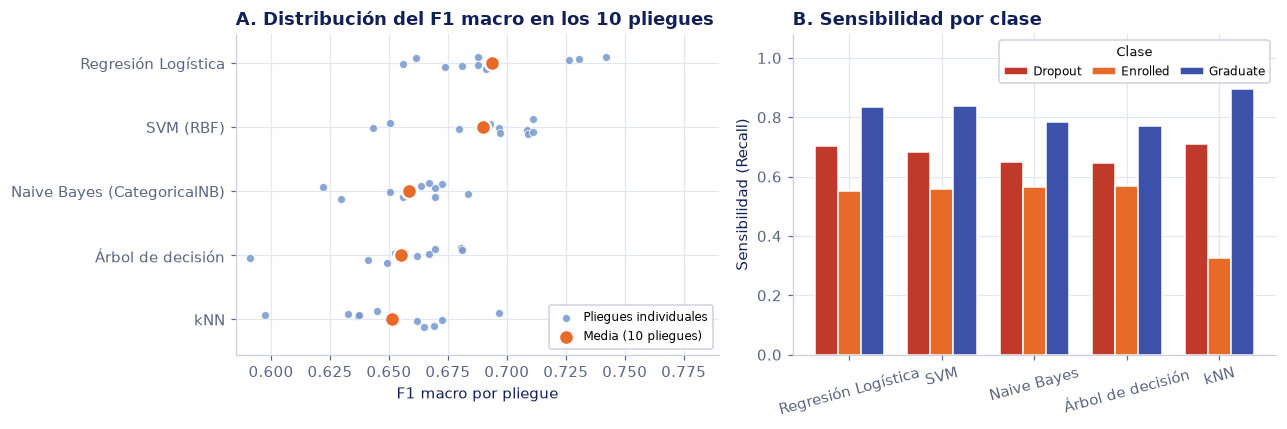

In [24]:
# Panel 1: Desempeño por pliegue
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.0))

orden_modelos = tabla_comparativa.index[::-1]
rng = np.random.default_rng(SEMILLA)

for fila, nombre in enumerate(orden_modelos):
    valores = f1_por_pliegue[nombre]
    axes[0].scatter(
        valores, fila + rng.uniform(-0.14, 0.14, len(valores)),
        s=28, color=AZUL, alpha=0.85, edgecolor="white", linewidth=0.6,
        label="Pliegues individuales" if fila == 0 else None
    )
    axes[0].scatter(
        valores.mean(), fila,
        s=95, color=NARANJA, edgecolor="white", linewidth=1.5, zorder=3,
        label="Media (10 pliegues)" if fila == 0 else None
    )

axes[0].set_yticks(range(len(orden_modelos)), orden_modelos)
axes[0].set_xlim(0.585, 0.79)
axes[0].set_ylim(-0.55, 4.45)
axes[0].set_xlabel("F1 macro por pliegue")
axes[0].set_title("A. Distribución del F1 macro en los 10 pliegues")
axes[0].legend(
    loc="lower right",
    fontsize=8,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.45,
    handletextpad=0.4,
)

# Panel 2: Sensibilidad por clase en cada clasificador
x_pos = np.arange(len(tabla_comparativa.index))
ancho = 0.25
for idx_c, (clase, col_c) in enumerate(zip(CLASES, [ROJO, NARANJA, AZUL_MEDIO])):
    axes[1].bar(
        x_pos + (idx_c - 1) * ancho,
        tabla_comparativa[f"Sens. {clase}"],
        width=ancho, color=col_c, edgecolor="white", label=clase
    )

axes[1].set_xticks(x_pos, [m.split(" (")[0] for m in tabla_comparativa.index], rotation=15)
axes[1].set_ylim(0, 1.08)
axes[1].set_ylabel("Sensibilidad (Recall)")
axes[1].set_title("B. Sensibilidad por clase")
axes[1].legend(
    title="Clase",
    loc="upper right",
    ncol=3,
    fontsize=8,
    title_fontsize=8.5,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.4,
    columnspacing=0.8,
    handletextpad=0.4,
)

plt.tight_layout()
plt.show()

**Lectura.** Al comparar los cinco modelos concluimos lo siguiente:
1. **Panel A:** La **Regresión Logística (`0.6938 ± 0.0281`)** y el **SVM con kernel RBF (`0.6900 ± 0.0235`)** obtienen los mejores resultados, superando por más de 3.5 puntos porcentuales al resto de clasificadores: **Naive Bayes Categórico (`0.6583 ± 0.0184`)**, el **Árbol de decisión (`0.6550 ± 0.0246`)** y **KNN (`0.6514 ± 0.0261`)**.

2. **Panel B:** Se muestra que los cinco clasificadores logran una sensibilidad alta en `Graduate` (entre 77 % y 89 %) y aceptable en `Dropout` (entre 64 % y 71 %).  
La diferencia principal está en el equilibrio con la clase minoritaria **`Enrolled`** (barras naranjas): mientras que kNN apenas detecta al **32.6 %** de los alumnos que siguen inscritos, la Regresión Logística y el SVM alcanzan una sensibilidad de **55.3 % y 55.8 %** en `Enrolled` manteniendo a la vez una alta especificidad en `Dropout` (~92.7–93.4 %) y en `Graduate` (~81.7–82.7 %).

---

## 6. Matriz de confusión del mejor clasificador y análisis de la clase `Dropout`

Tomamos nuestro mejor clasificador (**Regresión Logística**, F1 macro = `0.6938`) y analizamos su matriz de confusión construida con las predicciones de validación cruzada sobre los 3,539 estudiantes de entrenamiento, tanto en conteos absolutos como normalizada por fila (porcentaje real de cada clase).

Reporte de clasificación (Regresión Logística en validación cruzada):
              precision    recall  f1-score   support

     Dropout     0.8195    0.7027    0.7566      1137
    Enrolled     0.4471    0.5528    0.4944       635
    Graduate     0.8280    0.8336    0.8308      1767

    accuracy                         0.7412      3539
   macro avg     0.6982    0.6964    0.6939      3539
weighted avg     0.7569    0.7412    0.7466      3539



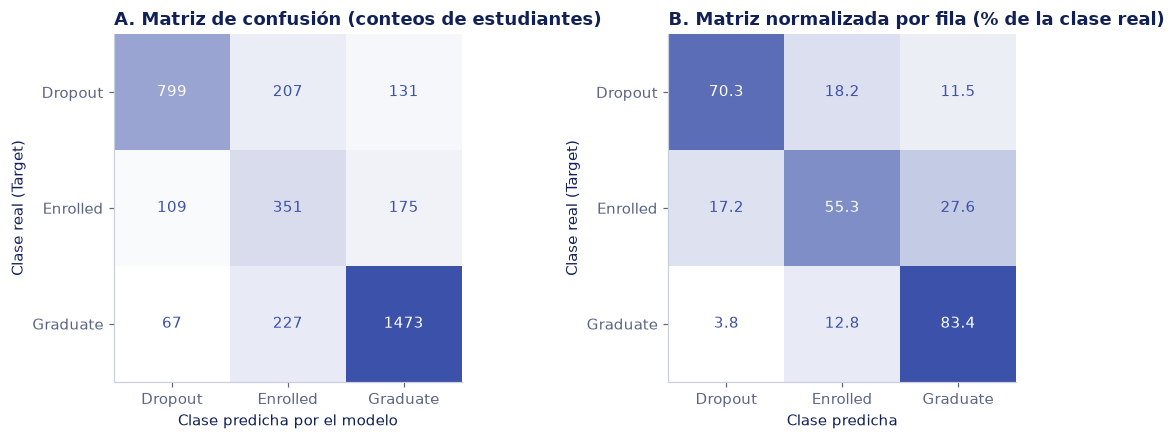

Perfil promedio de los 1,137 desertores reales según la clase en que los ubicó el clasificador:


,Casos (n),Curricular units 1st sem (approved),Tasa aprob. 1er sem (%),Curricular units 1st sem (grade),Tuition fees up to date,Scholarship holder,Tasa aprob. 2do sem (%)
Prediccion,,,,,,,
Dropout,799,1.75,25.17,5.72,0.55,0.06,19.19
Enrolled,207,3.68,61.26,11.00,0.95,0.10,47.17
Graduate,131,5.69,82.77,11.50,0.96,0.32,62.92


In [25]:
pred_mejor = predicciones_cv["Regresión Logística"]
matriz_abs = confusion_matrix(y, pred_mejor, labels=CLASES)
matriz_pct = confusion_matrix(y, pred_mejor, labels=CLASES, normalize="true") * 100

print("Reporte de clasificación (Regresión Logística en validación cruzada):")
print(classification_report(y, pred_mejor, labels=CLASES, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.1))

ConfusionMatrixDisplay(matriz_abs, display_labels=CLASES).plot(
    ax=axes[0], cmap=MAPA_AZULES, colorbar=False, values_format="d"
)
axes[0].grid(False)
axes[0].set_title("A. Matriz de confusión (conteos de estudiantes)")
axes[0].set_xlabel("Clase predicha por el modelo")
axes[0].set_ylabel("Clase real (Target)")

ConfusionMatrixDisplay(matriz_pct, display_labels=CLASES).plot(
    ax=axes[1], cmap=MAPA_AZULES, colorbar=False, values_format=".1f"
)
axes[1].grid(False)
axes[1].set_title("B. Matriz normalizada por fila (% de la clase real)")
axes[1].set_xlabel("Clase predicha")
axes[1].set_ylabel("Clase real (Target)")

plt.tight_layout()
plt.show()

# Análisis de los estudiantes reales de la clase Dropout según lo que predijo el modelo
desertores_analisis = entrena_crudo[y == "Dropout"].copy()
desertores_analisis["Prediccion"] = pred_mejor[y == "Dropout"]
desertores_analisis["Tasa aprob. 1er sem (%)"] = np.where(
    desertores_analisis["Curricular units 1st sem (enrolled)"] > 0,
    (desertores_analisis["Curricular units 1st sem (approved)"] / desertores_analisis["Curricular units 1st sem (enrolled)"]) * 100,
    0.0
)
desertores_analisis["Tasa aprob. 2do sem (%)"] = np.where(
    desertores_analisis["Curricular units 2nd sem (enrolled)"] > 0,
    (desertores_analisis["Curricular units 2nd sem (approved)"] / desertores_analisis["Curricular units 2nd sem (enrolled)"]) * 100,
    0.0
)

perfil_desertores = desertores_analisis.groupby("Prediccion")[[
    "Curricular units 1st sem (approved)",
    "Tasa aprob. 1er sem (%)",
    "Curricular units 1st sem (grade)",
    "Tuition fees up to date",
    "Scholarship holder",
    "Tasa aprob. 2do sem (%)",
]].mean().reindex(CLASES).round(2)

perfil_desertores.insert(0, "Casos (n)", desertores_analisis["Prediccion"].value_counts().reindex(CLASES))
print("Perfil promedio de los 1,137 desertores reales según la clase en que los ubicó el clasificador:")
display(perfil_desertores)

**Lectura.**

Observemos específicamente la clase `Dropout` (desertor):  
De los 1,137 estudiantes que realmente desertaron (`Dropout`), nuestro clasificador identifica correctamente a **799 (el 70.3 %)** al cierre del primer semestre, con una precisión de **82.0 %** (es decir, más de 8 de cada 10 alertas de deserción son verdaderas) y una especificidad de **92.7 %**.

Cuando el modelo se equivoca al clasificar a un desertor real (esto es, los 338 falsos negativos restantes), se confunde principalmente con la clase `Enrolled` (207 estudiantes, el 18.2 % de los desertores) y en menor medida con `Graduate` (131 estudiantes, el 11.5 %).

**¿Por qué ocurre esta confusión?**

La tabla del perfil promedio de los desertores nos da información para entender qué tienen en común esos casos:
1. **Sobre los que se confunden con `Enrolled`:** Los 799 desertores detectados tuvieron un tropiezo desde el primer semestre: apenas aprobaron 1.75 materias (que representa el 25.2 % de su carga), su nota promedio fue de **5.72** y solo el **55%** estaba al corriente en su colegiatura.  

    En cambio, los 207 desertores clasificados como `Enrolled` aprobaron en promedio 3.68 materias (el 61.3% de su carga) con calificación de **11.00**, y el **95%** tenía sus colegiaturas al día. Es decir, al terminar el primer semestre, estos 207 alumnos presentaban el mismo perfil de un estudiante regular con rezago ligero (`Enrolled`): reprobaron una o dos materias, pero seguían activos y al corriente en sus pagos.
    
    La última columna de la tabla muestra lo que pasó después: en el segundo semestre su tasa de aprobación cayó del **61.3% al 47.2%**, momento en que abandonaron.

2. **Sobre los que se confunden con `Graduate`:** Estos 131 casos son aún más interesantes: en el primer semestre aprobaron en promedio 5.69 materias (el 82.8% de su carga) con nota de **11.50**, el **96%** tenía sus pagos al corriente y el **32%** tenía beca. Académicamente tuvieron un buen primer semestre, indistinguible del de un graduado.

    Dado que el conjunto de datos no registra el motivo de la baja, solo podemos observar que su rendimiento bajó después del primer semestre (en el segundo semestre su aprobación cayó a 62.9 %). Por ello, podemos plantear la hipótesis de que su deserción se debe a factores ocurridos después del corte (como cambios de carrera o de institución, situaciones personales o económicas, inserción laboral, etc.), que no se pueden anticipar únicamente con el historial del primer semestre.

---

## 7. ¿Cuánto mejoraría el clasificador si esperáramos al cierre del segundo semestre?

Una pregunta clave para el diseño del modelo institucional es si vale la pena tomar la decisión al cierre del primer semestre o si convendría esperar medio año más para contar con las 6 variables adicionales de desempeño (`Curricular units 2nd sem ...`).

Para analizar esto, extendemos la función de indicadores y el `ColumnTransformer` del mejor clasificador (**Regresión Logística**) para agregar las 6 variables del segundo semestre, junto con su tasa de aprobación del segundo semestre y el cambio de materias aprobadas entre el 1er y el 2do semestre; y lo evaluamos sobre los mismos 10 pliegues estratificados.

,Al cierre del 1er semestre,Al cierre del 2do semestre,Cambio al esperar (+2do sem)
F1 macro (media),0.6938,0.7197,0.0259
F1 macro (desv. est.),0.0281,0.0285,0.0004
Exactitud global,0.7412,0.7658,0.0246
F1 Dropout,0.7566,0.7869,0.0303
F1 Enrolled,0.4944,0.5244,0.0300
F1 Graduate,0.8308,0.8480,0.0172
Sensibilidad Dropout,0.7027,0.7388,0.0361
Sensibilidad Enrolled,0.5528,0.5764,0.0236
Sensibilidad Graduate,0.8336,0.8512,0.0175


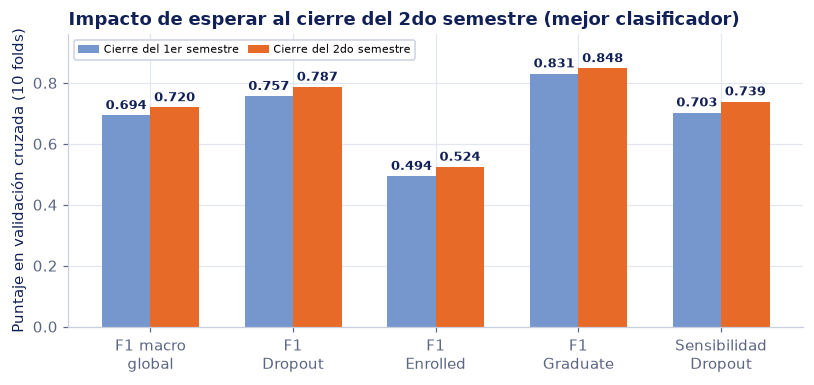

In [26]:
COLUMNAS_1S_Y_2S = [c for c in entrena_crudo.columns if c not in ["id", "Target"]]
X_2sem = entrena_crudo[COLUMNAS_1S_Y_2S].copy()


def agregar_indicadores_2do_semestre(df):
    '''Extiende los indicadores del 1er semestre con los del 2do semestre.'''
    df = agregar_indicadores_1er_semestre(df)
    ins2 = df["Curricular units 2nd sem (enrolled)"]
    apr2 = df["Curricular units 2nd sem (approved)"]
    eva2 = df["Curricular units 2nd sem (evaluations)"]
    nota2 = df["Curricular units 2nd sem (grade)"]

    df["tasa_aprobacion_2s"] = np.where(ins2 > 0, apr2 / ins2, 0.0)
    df["tasa_aprob_eval_2s"] = np.where(eva2 > 0, apr2 / eva2, 0.0)
    df["reprobadas_2s"] = np.maximum(0, ins2 - apr2)
    df["eval_fallidas_2s"] = np.maximum(0, eva2 - apr2)
    df["todo_aprobado_2s"] = ((ins2 > 0) & (apr2 == ins2)).astype(int)
    df["nada_aprobado_2s"] = ((ins2 > 0) & (apr2 == 0)).astype(int)
    df["cambio_aprobadas"] = apr2 - df["Curricular units 1st sem (approved)"]
    df["cambio_nota"] = nota2 - df["Curricular units 1st sem (grade)"]
    return df


muestra_2s = agregar_indicadores_2do_semestre(X_2sem.head(5))
BINARIOS_2S = BINARIOS_TOTAL + ["todo_aprobado_2s", "nada_aprobado_2s"]
NUMERICOS_2S = [c for c in muestra_2s.columns if c not in NOMINALES_MULTICLASE + BINARIOS_2S]
COLS_BINS_2S = COLS_BINS + [
    "Curricular units 2nd sem (enrolled)", "Curricular units 2nd sem (evaluations)",
    "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)",
    "tasa_aprobacion_2s", "reprobadas_2s"
]

pre_log_2s = ColumnTransformer([
    ("nom", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=8, sparse_output=False), NOMINALES_MULTICLASE),
    ("num", StandardScaler(), NUMERICOS_2S),
    ("bins", KBinsDiscretizer(n_bins=5, encode="onehot-dense", strategy="quantile"), COLS_BINS_2S),
    ("bin", "passthrough", BINARIOS_2S),
])

modelo_1sem = busqueda_log.best_estimator_
modelo_2sem = Pipeline([
    ("indicadores", FunctionTransformer(agregar_indicadores_2do_semestre)),
    ("prep", pre_log_2s),
    ("clf", LogisticRegression(
        penalty=busqueda_log.best_params_["clf__penalty"],
        solver=busqueda_log.best_params_["clf__solver"],
        C=busqueda_log.best_params_["clf__C"],
        class_weight=busqueda_log.best_params_["clf__class_weight"],
        max_iter=800,
        random_state=SEMILLA,
    )),
])

cv_1sem = cross_validate(modelo_1sem, X, y, cv=pliegues, scoring=["f1_macro", "accuracy"], n_jobs=-1)
cv_2sem = cross_validate(modelo_2sem, X_2sem, y, cv=pliegues, scoring=["f1_macro", "accuracy"], n_jobs=-1)
pred_2sem = cross_val_predict(modelo_2sem, X_2sem, y, cv=pliegues, n_jobs=-1)

f1_clase_1s = f1_score(y, pred_mejor, labels=CLASES, average=None)
f1_clase_2s = f1_score(y, pred_2sem, labels=CLASES, average=None)
sens_1s = [confusion_matrix(y, pred_mejor, labels=CLASES, normalize="true")[i, i] for i in range(3)]
sens_2s = [confusion_matrix(y, pred_2sem, labels=CLASES, normalize="true")[i, i] for i in range(3)]

comparacion_semestres = pd.DataFrame({
    "Al cierre del 1er semestre": [
        cv_1sem["test_f1_macro"].mean(),
        cv_1sem["test_f1_macro"].std(),
        cv_1sem["test_accuracy"].mean(),
        *f1_clase_1s,
        *sens_1s,
    ],
    "Al cierre del 2do semestre": [
        cv_2sem["test_f1_macro"].mean(),
        cv_2sem["test_f1_macro"].std(),
        cv_2sem["test_accuracy"].mean(),
        *f1_clase_2s,
        *sens_2s,
    ],
}, index=[
    "F1 macro (media)", "F1 macro (desv. est.)", "Exactitud global",
    "F1 Dropout", "F1 Enrolled", "F1 Graduate",
    "Sensibilidad Dropout", "Sensibilidad Enrolled", "Sensibilidad Graduate"
])
comparacion_semestres["Cambio al esperar (+2do sem)"] = (
    comparacion_semestres["Al cierre del 2do semestre"] - comparacion_semestres["Al cierre del 1er semestre"]
)
display(comparacion_semestres.round(4))

# Gráfica comparativa 1er vs 2do semestre
fig, ax = plt.subplots(figsize=(7.5, 3.6))
metricas_graf = ["F1 macro (media)", "F1 Dropout", "F1 Enrolled", "F1 Graduate", "Sensibilidad Dropout"]
x_m = np.arange(len(metricas_graf))
ancho_m = 0.34

b1 = ax.bar(x_m - ancho_m / 2, comparacion_semestres.loc[metricas_graf, "Al cierre del 1er semestre"], width=ancho_m, color=AZUL, label="Cierre del 1er semestre")
b2 = ax.bar(x_m + ancho_m / 2, comparacion_semestres.loc[metricas_graf, "Al cierre del 2do semestre"], width=ancho_m, color=NARANJA, label="Cierre del 2do semestre")

for barras in [b1, b2]:
    for b in barras:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.3f}", ha="center", va="bottom", fontsize=8.5, color=AZUL_OSCURO, fontweight="bold")

ax.set_xticks(x_m, ["F1 macro\nglobal", "F1\nDropout", "F1\nEnrolled", "F1\nGraduate", "Sensibilidad\nDropout"])
ax.set_ylim(0, 0.96)
ax.set_ylabel("Puntaje en validación cruzada (10 folds)")
ax.set_title("Impacto de esperar al cierre del 2do semestre (mejor clasificador)")
ax.legend(
    loc="upper left",
    ncol=3,
    fontsize=7,
    frameon=True,
    facecolor="white",
    edgecolor="#C9CFDF",
    framealpha=0.95,
    borderpad=0.4,
    columnspacing=0.8,
    handletextpad=0.4,
)
plt.tight_layout()
plt.show()

**Lectura.**

**¿Conviene esperar al cierre del segundo semestre?**  

Al incluir las calificaciones y materias aprobadas del segundo semestre, el F1 macro del clasificador sube de `0.6938` a `0.7197` (+2.59 puntos porcentuales) y la exactitud pasa de **74.1% a 76.6%**. La ganancia se distribuye principalmente en `Dropout` (cuyo F1 sube +3.00 puntos, de 0.757 a 0.787, aumentando la sensibilidad de **70.3% a 73.9%**, es decir, se detectaron 41 desertores más) y en `Enrolled` (cuyo F1 sube +3.00 puntos, de 0.494 a 0.524).

Aun así, razonando el problema a nivel práctico, opino que no conviene esperar al cierre del segundo semestre para tomar una decisión, sino que debería implementarse un esquema preventivo desde el primer semestre. Esto se sustenta en dos puntos:

1. La mayor deserción en educación superior ocurre precisamente durante el primer año. Al cierre del primer semestre, nuestro clasificador ya detecta al **70.3%** de todos los desertores (799 de 1,137), con una precisión del **82.0%**. Si la institución espera hasta el final del segundo semestre para ganar un 3.6% adicional de sensibilidad, para entonces la gran mayoría de esos 799 estudiantes ya habrá abandonado el instituto. El daño ya estaría hecho, tanto a nivel académico como financiero.

2. El modelo del primer semestre podría permitir identificar al cierre de este, quiénes necesitan tutorías académicas o apoyos financieros (esto en 7 de cada 10 alumnos en riesgo cuando todavía están inscritos).

    Y seis meses después, al cierre del segundo semestre, un segundo corte identifica a ese ~3.6 % adicional de alumnos que tuvieron un primer semestre regular (y por tanto no fueron detectados la primera vez), pero decayeron en el segundo (pasaron a estar en riesgo).

---

## 8. Entrenamiento del clasificador final y generación de predicciones de prueba

Entrenamos nuestro mejor clasificador (**Regresión Logística**) utilizando el **100% del conjunto de entrenamiento (3,539 estudiantes)** y generamos las predicciones para los **885 estudiantes del conjunto de prueba (`desercion-prueba.csv`)**.

El archivo se exporta bajo la carpeta `data/` de esta práctica (`../data/predicciones-prueba.csv`), y se incluye una copia en la raíz de la práctica (`../predicciones-prueba.csv`).
Incluimos las dos columnas de interés (`id` y `Target`) manteniendo los valores originales del conjunto de entrenamiento (`Dropout`, `Enrolled`, `Graduate`), y verificamos que la distribución predicha sea consistente con la población de entrenamiento.

In [27]:
clasificador_final = busqueda_log.best_estimator_
clasificador_final.fit(X, y)

pred_prueba = clasificador_final.predict(X_prueba_final)

entrega = pd.DataFrame({
    "id": prueba_crudo["id"].astype(int),
    "Target": pred_prueba,
})

# Guardamos el archivo CSV generado por el propio notebook
ruta_entrega_data = RUTA_DATOS / "predicciones-prueba.csv"
ruta_entrega_raiz = Path("../predicciones-prueba.csv")
entrega.to_csv(ruta_entrega_data, index=False)
entrega.to_csv(ruta_entrega_raiz, index=False)

# Verificaciones de integridad del archivo de entrega
assert list(entrega.columns) == ["id", "Target"], "Las columnas deben ser exactamente ['id', 'Target']"
assert len(entrega) == 885, f"Se esperaban 885 filas, se obtuvieron {len(entrega)}"
assert entrega["Target"].isna().sum() == 0, "No debe haber valores nulos en las predicciones"
assert set(entrega["Target"].unique()).issubset({"Dropout", "Enrolled", "Graduate"}), "Valores de Target inválidos"

print(f"Archivo generado en: {ruta_entrega_data} y {ruta_entrega_raiz}")
print(f"Dimensiones del archivo         : {entrega.shape[0]} filas × {entrega.shape[1]} columnas\n")

# Comparamos la proporción de clases en entrenamiento, validación cruzada y prueba
comparacion_dist = pd.DataFrame({
    "Real (entrenamiento, n=3,539)": (y.value_counts(normalize=True) * 100).round(2),
    "Predicho en VC (entrena, n=3,539)": (pd.Series(pred_mejor).value_counts(normalize=True) * 100).round(2),
    "Predicho en prueba (n=885)": (entrega["Target"].value_counts(normalize=True) * 100).round(2),
    "Conteo en prueba (n=885)": entrega["Target"].value_counts(),
}).reindex(["Dropout", "Enrolled", "Graduate"])

display(comparacion_dist)
print("\nPrimeras 10 filas del archivo de predicciones generado:")
display(entrega.head(10))

Archivo generado en: ../data/predicciones-prueba.csv y ../predicciones-prueba.csv
Dimensiones del archivo         : 885 filas × 2 columnas



,"Real (entrenamiento, n=3,539)","Predicho en VC (entrena, n=3,539)",Predicho en prueba (n=885),Conteo en prueba (n=885)
Dropout,32.13,27.55,27.34,242
Enrolled,17.94,22.18,22.37,198
Graduate,49.93,50.27,50.28,445



Primeras 10 filas del archivo de predicciones generado:


,id,Target
0,6,Graduate
1,12,Graduate
2,15,Graduate
3,18,Enrolled
4,19,Graduate
5,29,Enrolled
6,43,Graduate
7,46,Graduate
8,49,Graduate
9,51,Graduate


**Lectura.** Las proporciones predichas sobre los 885 estudiantes del conjunto de prueba (`27.34 % Dropout`, `22.37 % Enrolled`, `50.28 % Graduate`) son consistentes con las proporciones que el mismo clasificador obtiene en validación cruzada sobre el conjunto de entrenamiento (`27.55 % Dropout`, `22.18 % Enrolled`, `50.27 % Graduate`).

El pequeño incremento en la proporción predicha de `Enrolled` (~22.4% vs. 17.9% real) es el efecto directo (y buscado) de los pesos moderados por clase (`PESOS_SUAVES`), que incrementan la sensibilidad sobre la clase minoritaria para maximizar el F1 macro global.

---

## 9. Discusión y conclusiones

A lo largo de esta práctica comparamos cinco familias de clasificadores bajo las mismas particiones de validación cruzada estratificada. A continuación se presentan las razones por las cuales cada modelo se comportó como lo hizo, para este problema:

1. **Regresión Logística (`F1 macro = 0.6938 ± 0.0281`, 1er lugar):**  
Fue el mejor clasificador de la práctica gracias a tres decisiones de su Pipeline:

   - Los indicadores del primer semestre (como la tasa de aprobación y el número de materias reprobadas), que resumen de forma directa cómo le fue al alumno.
   - Dividir las 9 variables numéricas principales en 5 rangos (`KBinsDiscretizer`), lo que le permitió asignar un peso distinto a cada "escalón" (por ejemplo, distinguir entre reprobar 0 materias y reprobar la primera) sin dejar de ser un modelo lineal sencillo.
   - La regularización $L_2 (C = 0.3)$ junto con los pesos moderados por clase (`Dropout`: 0.95, `Enrolled`: 1.60, `Graduate`: 0.75), que evitaron que las categorías con pocos alumnos tuvieran pesos exagerados y subieron la sensibilidad en Enrolled al 55.3%.

2. **Máquinas de Soporte Vectorial — SVM (`F1 macro = 0.6900 ± 0.0235`, 2do lugar):**  
   Obtuvo un desempeño muy cercano al primer lugar. El kernel Gaussiano RBF ($C = 1.2, \gamma = \text{"scale"}$) capturó de forma natural las interacciones suaves entre las notas de admisión, la situación de pago de colegiatura y las materias aprobadas en el primer semestre. Además, mostró menor varianza entre pliegues ($\pm 0.0235$) que la Regresión Logística.

3. **Naive Bayes — `CategoricalNB` (`F1 macro = 0.6583 ± 0.0184`, 3er lugar):**  
   Mostró la mejora más clara gracias al preprocesamiento: mientras que `GaussianNB` por omisión cayó hasta 0.511 (porque ajustar campanas normales sobre columnas binarias poco frecuentes produce varianzas casi nulas), agrupar las variables continuas en 6 cuantiles permitió que `CategoricalNB` ($\alpha = 0.01$) superara tanto al árbol de decisión como a KNN en menor tiempo (6 segundos).
   Su límite contra la Regresión Logística y el SVM está en que Naive Bayes asume que todas las columnas son independientes entre sí: como nuestra tabla incluye varias columnas derivadas de las mismas calificaciones y materias del primer semestre (aprobadas, reprobadas, tasa de aprobación, indicadores de todo o nada aprobado), el modelo multiplica todas esas probabilidades como si fueran hechos distintos y termina contando varias veces la misma evidencia académica.

4. **Árbol de decisión (`F1 macro = 0.6550 ± 0.0246`, 4to lugar):**  
   Al restringir su profundidad (`max_depth = 6`), exigir hojas de al menos 10 estudiantes y aplicar poda de complejidad-costo (`ccp_alpha = 0.002`), el árbol corrigió su tendencia al sobreajuste (que en el árbol sin restricción hundía el F1 macro a ~0.60). Sin embargo, un árbol individual divide el espacio con cortes ortogonales eje por eje, lo que le dificulta aproximar fronteras diagonales suaves cuando la decisión depende de la suma ponderada de distintos factores (becas, calificaciones, etc.).

5. **k Vecinos más Cercanos — kNN (`F1 macro = 0.6514 ± 0.0261`, 5to lugar):**  
   Aunque la selección supervisada de los 40 atributos más relevantes (`SelectKBest`) y el uso de la distancia Manhattan ($p = 1$, $k = 13$) mejoraron su F1 macro en más de 10 puntos respecto a su versión cruda, KNN es el modelo más afectado por la naturaleza del dataset (es mixto) y por el traslape de la clase minoritaria `Enrolled` (donde tuvo la sensibilidad más baja: 32.6 %).  
   En espacios de varias dimensiones donde se mezclan atributos discretos y continuos, los vecindarios locales de un estudiante `Enrolled` suelen estar dominados por estudiantes de las clases mayoritarias `Graduate` y `Dropout`.

---

### Declaración sobre el uso de IA Generativa

Este notebook fue elaborado con apoyo de modelos de lenguaje basados en IA (Antigravity / Gemini) como asistentes para la estructuración, depuración de código y revisión de redacción. El diseño experimental, el análisis crítico de las decisiones de preprocesamiento, la interpretación de resultados y la validación metodológica son responsabilidad del autor.

---

### Referencias

1. **Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022).** *Predicting Student Dropout and Academic Success*. Data, 7(11), 146. [https://doi.org/10.3390/data7110146](https://doi.org/10.3390/data7110146)
2. **UCI Machine Learning Repository (2021).** *Predict Students' Dropout and Academic Success (Dataset ID: 697)*. [https://archive.ics.uci.edu/dataset/697](https://archive.ics.uci.edu/dataset/697)
3. **Pedregosa, F. et al. (2011).** *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825–2830.
4. **López Nava, I. H. (2026).** *Cuadernos del curso Introducción a la Ciencia de Datos (Sesiones 11 a 16: Clasificación, Árboles, Aprendizaje Bayesiano, Instancias y SVM)*. Posgrado en Ciencias de la Computación, CICESE.